# Drive failure from 30-day SMART windows — Backblaze, 2022 to today, CNN vs XGBoost vs transformer

The same pipeline as `Dataset_backblaze_Analysis_2022.ipynb` — archives from **2022
onward** — with two more models added: **XGBoost** on a flattened summary of each 30-day
window, and a **transformer** over the window's days, both scored against the CNN on the
same test drives and the same windows.

| § | question | what gets printed |
|---|---|---|
| **1** | is any column a proxy for `failure`? | the leakage audit and the surviving feature set $X$ |
| **2** | can the model see the label at all? | **four executed checks**, not a claim |
| **3** | how many 30-day windows cover a drive's whole life? | per-drive window and **batch counts** |
| **4** | does this drive fail in *this* 30 days? (CNN) | a verdict per window, plus per-drive histograms |
| **4b** | when does the CNN start to overfit, and does its shape change that? | train-vs-validation divergence per variation, logged to `results/experiments_results.xlsx`, with the winner on a `Best Model` sheet |
| **5** | does gradient boosting on window summaries beat the CNN? | XGBoost training, test metrics, **CNN vs XGBoost** table and curves |
| **5b** | can a transformer beat the CNN? | five transformer variations under the CNN's protocol, then **CNN vs XGBoost vs transformer** on the same windows |
| **6** | how far does a single tree get? | a depth ladder up to **depth 8**, train vs test |
| **Summary** | which model is best? | all four models in one table, the winner by drive precision @100 and PR-AUC, and `results/model_comparison.xlsx` with every CNN, transformer and XGBoost run |

**Scope.** Archives `Q1_2022` through the newest quarter. A drive that was already in
service in 2021 enters with only its 2022-onward rows, which is the intended reading of
"from 2022 till today".

**Still the fleet, not a cohort.** No vendor filter and no matched sampling: failures are
a fraction of a percent of drive-days, as they are in a real datacentre.

In [1]:
import gc, json, os, sys, time
import numpy as np
import pandas as pd
import torch
import xgboost as xgb
import matplotlib.pyplot as plt

sys.path.insert(0, "scripts")
import leakage_audit as la
import backblaze_window_pipeline as bw
import archive_window_pipeline as ap

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 9})
pd.set_option("display.width", 220, "display.max_columns", 40)

SHARD_DIR  = os.environ.get("BACKBLAZE_SHARDS",
                            os.path.join("data", "backblaze_archive", "shards"))
STORE_DIR  = os.environ.get("BACKBLAZE_STORE_2022",
                            os.path.join("data", "backblaze_archive", "store_2022"))
SINCE_YEAR = int(os.environ.get("SINCE_YEAR", "2022"))
FIG_DIR    = "results/figures"
SEED       = 42
os.makedirs(FIG_DIR, exist_ok=True)
bw.set_seed(SEED)

shards = ap.shard_paths(SHARD_DIR, since_year=SINCE_YEAR)
print(f"torch {torch.__version__} | xgboost {xgb.__version__} | device "
      f"{'cuda' if torch.cuda.is_available() else 'cpu'}")
print(f"{len(shards)} shards from {SINCE_YEAR} on: "
      f"{os.path.basename(shards[0])[:-8]} -> {os.path.basename(shards[-1])[:-8]}")
print("  " + ", ".join(os.path.basename(p)[:-8] for p in shards))

torch 2.14.0.dev20260708+cu132 | xgboost 3.4.1 | device cuda
18 shards from 2022 on: Q1_2022 -> Q2_2026
  Q1_2022, Q2_2022, Q3_2022, Q4_2022, Q1_2023, Q2_2023, Q3_2023, Q4_2023, Q1_2024, Q2_2024, Q3_2024, Q4_2024, Q1_2025, Q2_2025, Q3_2025, Q4_2025, Q1_2026, Q2_2026


---
## 1 — Target-leakage audit

A leaked column is not *evidence about* the outcome but a *restatement of* it. In drive
telemetry it is almost never a SMART attribute; it hides in three places, and the audit
probes all three: the column values, the **missingness** pattern, and **record
geometry** — anything derived from where a row sits relative to the end of a drive's
record, because Backblaze writes `failure = 1` on a drive's last reporting day.

The audit samples by **drive**, never by drive-day: every geometry probe is derived from
a drive's own first and last day, and a drive whose rows have been thinned has neither.

In [2]:
t0 = time.time()
cfg0 = ap.ArchiveConfig(shard_dir=SHARD_DIR, store_dir=STORE_DIR,
                        since_year=SINCE_YEAR, random_state=SEED)
census = ap.build_drive_census(cfg0)

epoch = pd.Timestamp("1970-01-01")
print(f"\n{len(census):,} drives | {int(census.n_obs.sum()):,} observed drive-days | "
      f"{int(census.has_failure.sum()):,} drives with a failure event")
print(f"{epoch + pd.Timedelta(days=int(census.start_day.min())):%Y-%m-%d} -> "
      f"{epoch + pd.Timedelta(days=int(census.end_day.max())):%Y-%m-%d}"
      f"   ({time.time()-t0:.0f}s)")

  census cached: 416,428 drives

416,428 drives | 457,380,330 observed drive-days | 19,024 drives with a failure event
2022-01-01 -> 2026-06-30   (0s)


In [3]:
audit_df = ap.sample_audit_frame(cfg0, census, n_drives=15_000)
report = la.audit_frame(audit_df)
report.print_report()

  [ 1/18] Q1_2022.parquet    669,411 rows kept


  [ 2/18] Q2_2022.parquet    691,592 rows kept


  [ 3/18] Q3_2022.parquet    735,216 rows kept


  [ 4/18] Q4_2022.parquet    768,652 rows kept


  [ 5/18] Q1_2023.parquet    767,257 rows kept


  [ 6/18] Q2_2023.parquet    780,868 rows kept


... (10 outputs left out)

  [17/18] Q1_2026.parquet  1,104,216 rows kept


  [18/18] Q2_2026.parquet  1,156,039 rows kept


  audit frame: 16,417,355 drive-days over 15,000 drives, 656 failure events (base rate 0.00400%)
[audit] scoring 23 telemetry columns, 6 identifier/topology columns, and 6 derived record-geometry probes over 16,417,355 drive-days ...


STEP 1 -- TARGET LEAKAGE AND PROXY AUDIT
  drive-days ........... 16,417,355
  distinct drives ...... 15,000
  failure events ....... 656 (base rate 0.0040%)

  thresholds: severe if rank-AUC >= 0.95, or 1-threshold balanced acc >= 0.90,
              or |r| >= 0.50, or missingness gap >= 0.25, or level lift >= 20x

--------------------------------------------------------------------------------------------
A. TELEMETRY COLUMNS vs failure -- top 12 by rank AUC
--------------------------------------------------------------------------------------------
       column coverage  n_unique   corr auc_directional balanced_acc verdict
smart_187_raw   0.3930      1120 0.0174          0.8887       0.8785 suspect
smart_183_raw   0.0325       169 0.0006          0.7950       0.7586   clean
smart_197_raw   0.9685      1396 0.0651          0.7862       0.7842   clean
  smart_5_raw   0.9910      6815 0.0212          0.7859       0.7807   clean
smart_198_raw   0.9902       890 0.0640          0.7004  

15 attributes survive coverage >= 50% and the blocklist:

  smart_197_raw      coverage  96.85%      1,396 distinct  rank AUC 0.7862
  smart_5_raw        coverage  99.10%      6,815 distinct  rank AUC 0.7859
  smart_198_raw      coverage  99.02%        890 distinct  rank AUC 0.7004
  smart_4_raw        coverage  98.77%        423 distinct  rank AUC 0.6590
  smart_12_raw       coverage  99.82%        346 distinct  rank AUC 0.6403
  smart_9_raw        coverage  99.82%     82,565 distinct  rank AUC 0.6211
  smart_240_raw      coverage  65.79%     87,644 distinct  rank AUC 0.6022
  smart_193_raw      coverage  98.67%    136,319 distinct  rank AUC 0.5959
  smart_1_raw        coverage  99.74%  5,427,754 distinct  rank AUC 0.5781
  smart_7_raw        coverage  98.77%  5,873,176 distinct  rank AUC 0.5710
  smart_3_raw        coverage  98.77%      3,417 distinct  rank AUC 0.5443
  smart_192_raw      coverage  99.49%     16,010 distinct  rank AUC 0.5293
  smart_194_raw      coverage  99.82%     

  saved results/figures/2022x_step1_leakage_audit.png


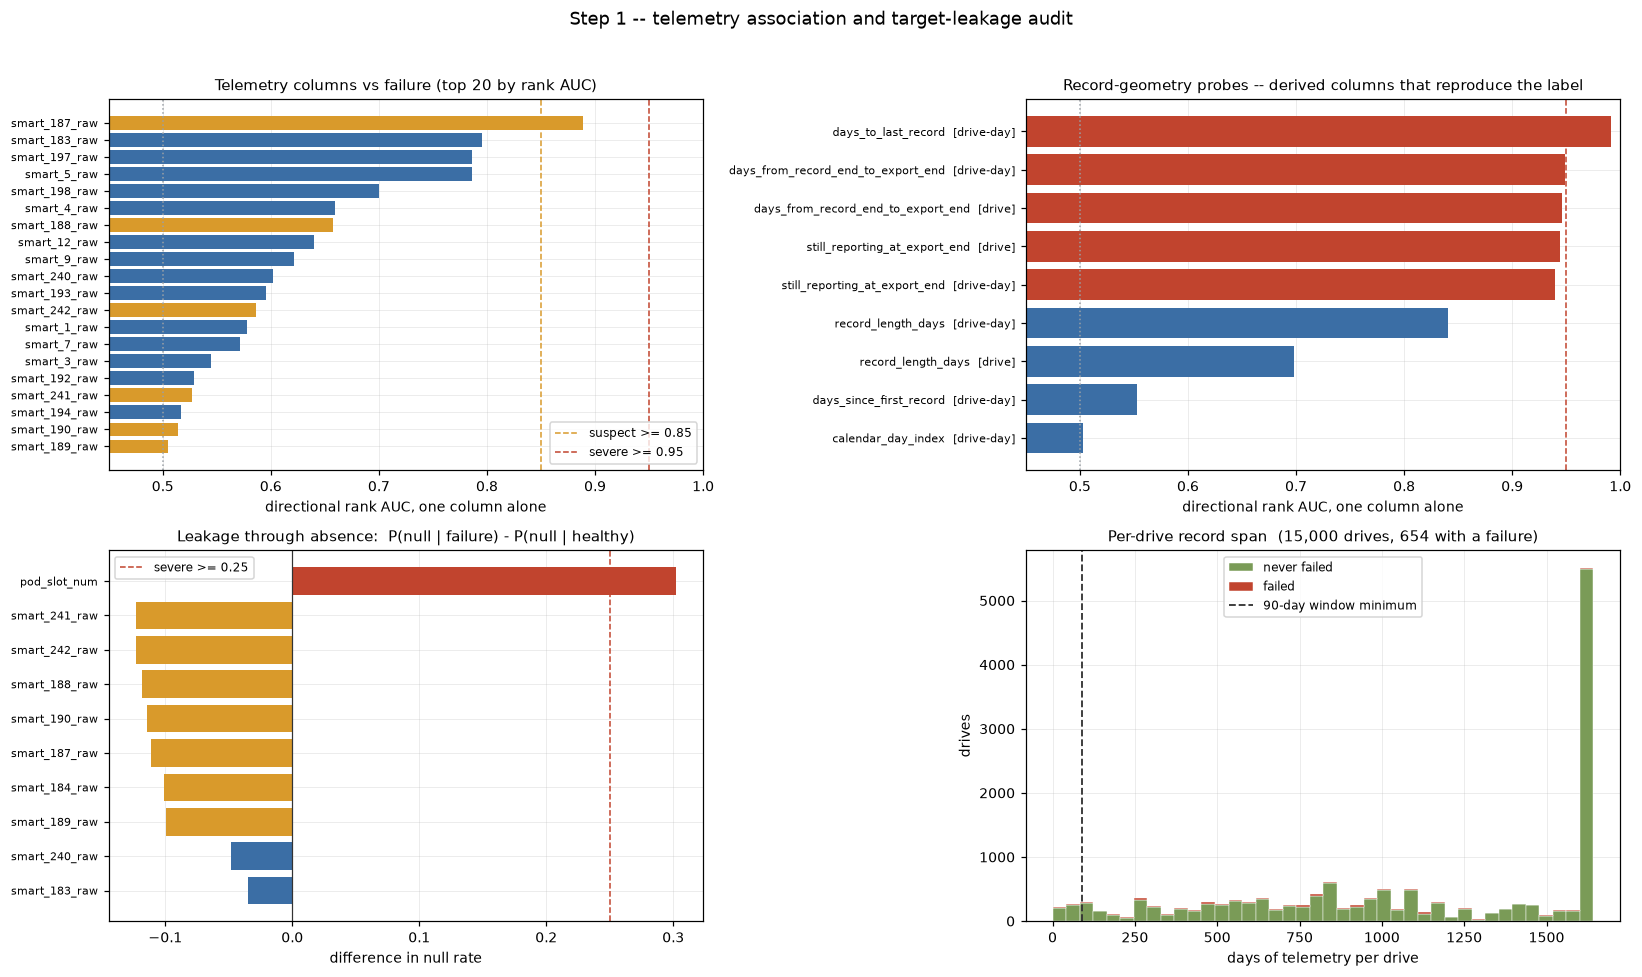

21499

In [4]:
features = la.select_feature_columns(audit_df, report)

print(f"{len(features)} attributes survive coverage >= {report.cfg.min_coverage:.0%} "
      f"and the blocklist:\n")
tbl = report.columns.set_index("column")
for c in features:
    r = tbl.loc[c]
    print(f"  {c:<18} coverage {100*r.coverage:6.2f}%  "
          f"{int(r.n_unique):>9,} distinct  rank AUC {r.auc_directional:.4f}")

report.assert_clean(features)          # raises if a blocked name reached X
la.plot_audit(report, save_path=f"{FIG_DIR}/2022x_step1_leakage_audit.png")
del audit_df; gc.collect()

---
## 2 — Building the store, then **proving** the label cannot be read

The dense matrix is built once and memory-mapped. `failure` is written to a *separate
file* from the feature matrix — it is not a column of `X` that gets dropped later, it
never enters `X` at all.

That is a claim, so the next cell tests it four ways:

1. **Names.** No channel is called `failure` or derived from it.
2. **Storage.** `values.f32` and `failure.u8` are different files and share no memory, so
   no write to one can surface in the other.
3. **Independence.** The label array is replaced with random noise and the same windows
   are gathered again. If a single byte of `X` depended on the label, `X` would move. It
   must come back bit-identical.
4. **Separability.** Every channel is scored against the window label on its own. A
   column that *was* the label would sit at AUC ≈ 1.0. The check fails the notebook if
   any channel exceeds 0.95.

Checks 1, 2 and 4 raise on failure; check 3 is the one that actually settles it, because
it is an experiment on the running code rather than an inspection of it.

In [5]:
cfg = ap.ArchiveConfig(
    shard_dir         = SHARD_DIR,
    store_dir         = STORE_DIR,
    since_year        = SINCE_YEAR,
    window_days       = 30,     # a sample is 30 consecutive days
    horizon_days      = 30,     # positive if the drive fails within 30 days of window end
    stride_days       = 1,      # every possible start is enumerated for eval
    min_days          = 30,     # shorter drives are dropped, not padded
    delta_lags        = (1, 7),
    add_observed_mask = True,
    feature_columns   = tuple(features),
    log1p_columns     = tuple(c for c in features
                              if c not in ("smart_194_raw", "smart_190_raw")),
    n_buckets         = 48,
    samples_per_drive = 4,
    train_positive_ratio = 0.25,
    batch_size        = 4096,
    random_state      = SEED,
)

store = ap.build_archive_store(cfg)

STEP A -- DRIVE CENSUS
  census cached: 416,428 drives

STEP B -- DENSE LAYOUT
  413,045 drives kept, 3,383 dropped (shorter than 30 days)
  459,048,144 dense drive-days (457,317,880 observed, 1,730,264 forward-filled)
  matrix 459,048,144 x 46 float32 = 84.5 GB memory-mapped

STEP C -- EXTERNAL SORT INTO 48 BUCKETS
  buckets cached

STEP D -- DENSIFY
  dense matrix cached

ArchiveSeriesStore: 413,045 drives, 459,048,144 dense drive-days, 46 channels (84 GB memory-mapped), 18,564 drives with a failure event


In [6]:
splits = ap.grouped_drive_split(store, cfg)
checks = ap.verify_no_label_leakage(store, splits["train"], n_probe=20_000, seed=SEED)

LABEL-LEAKAGE VERIFICATION
  1. names ........... 46 channels, none named after `failure`
  2. storage ......... values -> values.f32, labels -> failure.u8 (separate files, no shared memory)
  3. independence .... labels overwritten with noise; X re-gathered bit-identical over 4,096 windows  PASS
  4. separability .... 20,000 probe windows, 0.395% positive
     strongest single channel: smart_197_raw at AUC 0.6911 (a proxy would sit at ~1.00)

  the model input is (batch, 30, 46) and contains SMART levels, their deltas and the observed mask -- nothing else


In [7]:
# The strongest channels, ranked against the window label. Useful signal sits well short
# of the 0.95 line; a proxy would be pinned against 1.00.
top = checks["channel_scores"].head(12).reset_index(drop=True)
top.index += 1
print("strongest single channels vs the 30-day window label "
      f"({checks['n_probe_windows']:,} probe windows):\n")
print(top.to_string())
print(f"\nceiling for a non-leaked channel: 0.95     observed maximum: "
      f"{checks['max_channel_auc']:.4f}")
print(f"model input shape: (batch, {cfg.window_days}, {checks['n_channels']}) "
      f"-- SMART levels, 1- and 7-day deltas, observed mask. No label channel.")

strongest single channels vs the 30-day window label (20,000 probe windows):

           channel  auc_vs_window_label
1    smart_197_raw             0.691124
2      smart_5_raw             0.682798
3    smart_198_raw             0.648322
4      smart_1_raw             0.627615
5      smart_7_raw             0.622210
6   smart_5_raw_d7             0.618829
7    smart_193_raw             0.602454
8      smart_3_raw             0.599101
9   smart_7_raw_d1             0.594618
10  smart_9_raw_d1             0.592584
11   smart_240_raw             0.590284
12  smart_7_raw_d7             0.590062

ceiling for a non-leaked channel: 0.95     observed maximum: 0.6911
model input shape: (batch, 30, 46) -- SMART levels, 1- and 7-day deltas, observed mask. No label channel.


---
## 3 — Covering every drive's whole timeline with 30-day windows

Two different questions, two different window sets, both reported below.

**Tiling** lays non-overlapping 30-day blocks end to end along each drive's record:
$\lceil \text{record days} / 30 \rceil$ windows, so **every drive-day lands in exactly
one window** — nothing counted twice, nothing skipped. This is "as many batches as it
takes to fill the whole timeline", and it is what the decision tree in §5 is fitted on.
Where a record is not a multiple of 30, the last block is pulled back to end on the
drive's final day, so it overlaps its predecessor rather than running short.

**Stride-1 enumeration** is the other extreme: every possible start offset, used for the
sequence model's validation and test passes.

Both counts are printed, per split and per drive.

In [8]:
tiles = {name: ap.TilingWindows(store, splits[name], batch_size=cfg.batch_size,
                                split_name=name)
         for name in ("train", "val", "test")}

W = cfg.window_days
rows = []
for name in ("train", "val", "test"):
    idx, t = splits[name], tiles[name]
    rows.append({
        "split": name,
        "drives": len(idx),
        "drives with a failure": int(store.drive_has_failure[idx].sum()),
        "record days (dense)": int(store.lengths[idx].sum()),
        f"tiling {W}-day windows": t.n_windows,
        "tiling batches": len(t),
        "every possible window": int((store.lengths[idx] - W + 1).sum()),
    })
coverage = pd.DataFrame(rows).set_index("split")
print(coverage.to_string(formatters={c: "{:,}".format for c in coverage.columns
                                     if coverage[c].dtype.kind in "iu"}))

total_tiles = sum(t.n_windows for t in tiles.values())
total_batches = sum(len(t) for t in tiles.values())
print(f"\nTIMELINE COVERAGE")
print(f"  {store.n_drives:,} drives, {store.n_rows:,} dense drive-days")
print(f"  {total_tiles:,} non-overlapping {W}-day windows cover the entire timeline")
print(f"  at batch size {cfg.batch_size:,} that is {total_batches:,} batches in total")
for name in ("train", "val", "test"):
    print("  " + tiles[name].label_report())

       drives drives with a failure record days (dense) tiling 30-day windows tiling batches every possible window
split                                                                                                             
train 280,870                12,623         312,175,229            10,519,256          2,569           304,029,999
val    49,566                 2,228          55,215,887             1,860,545            455            53,778,473
test   82,609                 3,713          91,657,028             3,088,649            755            89,261,367

TIMELINE COVERAGE
  413,045 drives, 459,048,144 dense drive-days
  15,468,450 non-overlapping 30-day windows cover the entire timeline
  at batch size 4,096 that is 3,779 batches in total
  train | tiling W=30  |   10,519,256 windows | 280,870 drives | positive rate  0.2401% (25,254 positive windows) | 2,569 batches
  val   | tiling W=30  |    1,860,545 windows |  49,566 drives | positive rate  0.2391% (4,449 positive wi

In [9]:
# Per-drive accounting: how many windows each drive needs to have its whole record
# covered, and how much the final window had to overlap to stay a full 30 days.
cov = tiles["test"].coverage_report()
print(f"per-drive window counts, first 20 test drives "
      f"(batch size {cfg.batch_size:,}):\n")
print(cov.head(20).to_string(index=False))

n = cov["windows_to_cover_timeline"]
print(f"\nacross all {len(cov):,} test drives:")
print(f"  windows per drive .... min {n.min()}, median {int(n.median())}, "
      f"mean {n.mean():.1f}, max {n.max()}")
print(f"  total windows ........ {int(n.sum()):,}")
print(f"  total batches ........ {len(tiles['test']):,} "
      f"of up to {cfg.batch_size:,} windows each")
print(f"  days covered ......... {int(cov.days_covered.sum()):,} "
      f"(record holds {int(cov.record_days.sum()):,}; the difference is the "
      f"overlap pulled back onto the last window of each drive)")

per-drive window counts, first 20 test drives (batch size 4,096):

 drive_index    serial_number  record_days  windows_to_cover_timeline  days_covered  overlap_on_last_window  drive_has_failure
           3 02308a3415be0010         1642                         55          1650                       8              False
           7 0559e3d009d20010          993                         34          1020                      27              False
           8 0564f6f3fab90010         1642                         55          1650                       8              False
           9 059bba587f390010          993                         34          1020                      27              False
          15 078ea1af2c3f0010         1642                         55          1650                       8              False
          26 0e4aa019c4690010         1642                         55          1650                       8              False
          29     1030A004F9RG          252  

In [10]:
bundle = ap.build_archive_bundle(cfg, store=store, val_stride=1, verbose=True)


grouped split by drive id -- no drive appears in two splits:
  train  280,870 drives  (12,623 carry a failure, 4.49%)
  val     49,566 drives  (2,228 carry a failure, 4.50%)
  test    82,609 drives  (3,713 carry a failure, 4.49%)
  scaler cached -- matrix already standardised in place

Window datasets (window_days=30, horizon_days=30, stride_days=1):
  train | random spd 4   |    1,123,480 windows | 280,870 drives | positive rate  1.1078% (measured, 12,623 failing drives)


  val   | enumerate stride 1  |   53,778,473 windows |  49,566 drives | positive rate  0.1277% (68,656 positive windows)
  test  | enumerate stride 1  |   89,261,367 windows |  82,609 drives | positive rate  0.1287% (114,854 positive windows)

Raw pos_weight from the training positive rate: 89.3


---
## 4 — Training, then a verdict for every 30-day window

A 1D-CNN over the sequence: dilated temporal blocks so the receptive field spans the
full 30 days, then global pooling to one logit per window.
`(batch, 30, channels) → (batch, 1)`.

**One imbalance correction, not two.** The sampler forces 25% of the windows drawn from
failing drives to be positive ones, and the loss is plain BCE. Correcting twice — a
balanced sampler *and* a large `pos_weight` — is the mistake documented in
`TOSHIBA_PIPELINE.md`.

**Early stopping on validation PR-AUC.** At a base rate near 0.1%, accuracy is
meaningless: predicting "healthy" every time scores over 99.8%. Validation *loss* is not
used either: the model trains on a resampled stream, so its probabilities drift in
calibration while its ranking improves. The earlier run shows exactly that, with val
loss rising from epoch 3 to 4 while val PR-AUC rose too. The weights from the best
epoch are restored at the end.

### Choosing the architecture by experiment, not by assumption

The CNN's shape was previously a guess: five temporal blocks, 64 channels, dropout 0.2.
`scripts/run_cnn_search.py` replaces the guess with a search. It is handed a **list of
options** -- `ap.CNN_SEARCH_SPACE` -- and runs one short training run per configuration,
ranking them on the **same** validation windows:

| option | values offered |
|---|---|
| `dilations` | 2 to 6 blocks: `1-2`, `1-2-4`, `1-2-4-8`, `1-2-4-8-16`, `1-2-4-8-16-32`, `1-1-2-2-4-4` |
| `hidden_dim` | 32, 64, 96, 128 |
| `dropout` | 0.1, 0.2, 0.3 |
| `lr` | 3e-4, 1e-3, 3e-3 |
| `kernel_size` | 3, 5 |
| `weight_decay` | 1e-5, 1e-4 |
| `train_positive_ratio` | 0.15, 0.25, 0.40 |

Each `dilations` entry is one temporal block, so the search **adds and removes layers**
as well as resizing them. The full grid is 2,592 combinations; the run below is a random
sample of it, which explores each individual knob far better than an exhaustive sweep of
a few of them would.

The cell loads the cached result if the search has already been run; pass
`--trials`/`--epochs` to `scripts/run_cnn_search.py` to redo it.

In [11]:
SEARCH_CSV = "results/w2022x_cnn_search.csv"
if os.path.exists(SEARCH_CSV):
    search = pd.read_csv(SEARCH_CSV)
    print(f"loaded {len(search)} cached trials from {SEARCH_CSV}")
else:
    search = ap.cnn_search(cfg, store, bundle.splits, mode="random", n_trials=30,
                           epochs=3, val_stride=30, seed=SEED, out_csv=SEARCH_CSV)

show = ["layers", "dilations", "kernel_size", "hidden_dim", "dropout", "lr",
        "weight_decay", "train_positive_ratio", "parameters", "val_pr_auc",
        "val_roc_auc"]
print()
print("top 10 configurations by validation PR-AUC:")
print()
print(search[show].head(10).to_string(index=False))
print()
print("how depth alone scores (median over the trials at each layer count):")
print(search.groupby("layers")["val_pr_auc"].agg(["count", "median", "max"])
      .round(4).to_string())

loaded 30 cached trials from results/w2022x_cnn_search.csv

top 10 configurations by validation PR-AUC:

 layers     dilations  kernel_size  hidden_dim  dropout    lr  weight_decay  train_positive_ratio  parameters  val_pr_auc  val_roc_auc
      5    1-2-4-8-16            3         128      0.1 0.001       0.00001                  0.25      519297    0.145695     0.877631
      3         1-2-4            3          96      0.3 0.003       0.00001                  0.40      185569    0.144153     0.880100
      4       1-2-4-8            5          96      0.1 0.001       0.00010                  0.40      379297    0.143606     0.878669
      6 1-2-4-8-16-32            5         128      0.2 0.001       0.00001                  0.40      990593    0.143038     0.884129
      6   1-1-2-2-4-4            3          64      0.1 0.003       0.00001                  0.25      161729    0.142635     0.876482
      6 1-2-4-8-16-32            3         128      0.2 0.003       0.00001          

In [12]:
best = search.iloc[0]
BEST_DILATIONS = tuple(int(d) for d in str(best.dilations).split("-"))
print(f"winner: {int(best.layers)} layers, dilations {best.dilations}, "
      f"kernel {int(best.kernel_size)}, hidden {int(best.hidden_dim)}, "
      f"dropout {best.dropout}, lr {best.lr:g}, wd {best.weight_decay:g}, "
      f"positive_ratio {best.train_positive_ratio}")
print(f"  {int(best.parameters):,} parameters, search val PR-AUC {best.val_pr_auc:.4f}")

prev = search[(search.layers == 5) & (search.hidden_dim == 64)
              & (search.kernel_size == 3)]
if len(prev):
    print(f"  the previous hand-picked shape (5 layers, hidden 64, kernel 3) scored "
          f"{prev.val_pr_auc.max():.4f} -> "
          f"{100*(best.val_pr_auc/prev.val_pr_auc.max()-1):+.1f}%")

# The sampler's positive ratio was searched too, so the training set is rebuilt if the
# winner disagrees with the ratio the bundle was constructed with.
if float(best.train_positive_ratio) != cfg.train_positive_ratio:
    bundle.datasets["train"] = ap.RandomWindows(
        store, bundle.splits["train"], samples_per_drive=cfg.samples_per_drive,
        positive_ratio=float(best.train_positive_ratio), batch_size=cfg.batch_size,
        seed=SEED, split_name="train")
    print(f"  rebuilt the training sampler at positive_ratio "
          f"{float(best.train_positive_ratio)} (was {cfg.train_positive_ratio})")

winner: 5 layers, dilations 1-2-4-8-16, kernel 3, hidden 128, dropout 0.1, lr 0.001, wd 1e-05, positive_ratio 0.25
  519,297 parameters, search val PR-AUC 0.1457
  the previous hand-picked shape (5 layers, hidden 64, kernel 3) scored 0.1382 -> +5.5%


In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Architecture and optimiser settings come from the search above, not from a guess.
tcfg = bw.TrainConfig(
    arch="cnn", hidden_dim=int(best.hidden_dim), dropout=float(best.dropout),
    dilations=BEST_DILATIONS, kernel_size=int(best.kernel_size),
    batch_size=cfg.batch_size, lr=float(best.lr),
    # The previous run (max_epochs=6) had its best epoch at 6: it was cut off while still
    # improving, never early-stopped. 20 epochs leaves room for the curves to turn.
    weight_decay=float(best.weight_decay), max_epochs=20, patience=3,
    loss="bce", sampler="none",
    # num_workers=0 on purpose: a batch is ~23 MB and worker IPC costs several times
    # what the gather itself does -- 8 workers measured 7x slower than none.
    num_workers=0, seed=SEED,
)

loaders = ap.build_loaders(bundle, tcfg, device)
bw.set_seed(SEED)       # the same initial weights the variation sweep gives its baseline
model = bw.build_model(bundle.num_features, cfg.window_days, tcfg).to(device)
with torch.no_grad():
    probe = torch.zeros(2, cfg.window_days, bundle.num_features, device=device)
    print(f"input (2, {cfg.window_days}, {bundle.num_features}) -> "
          f"{tuple(model(probe).shape)}  (one logit per window)")
print(f"{bw.count_parameters(model):,} trainable parameters on {device}")

input (2, 30, 46) -> (2, 1)  (one logit per window)
519,297 trainable parameters on cuda


### Measuring overfitting: a train probe that can be compared with validation

Overfitting shows as training performance pulling away from validation performance. The
training loss the loop has always reported cannot show that, for two reasons:

* it is measured on the **resampled** stream: `RandomWindows` pushes a share of draws
  onto failure regions, so the stream runs at about 1.5% positives against
  validation's 0.2%. In the last run that alone made the training loss about **3× higher**
  than the validation loss (0.046 vs 0.015), the opposite of what overfitting looks like;
* it is measured with dropout on, while the weights move under it.

So every epoch now also scores a **train probe**: a fixed set of windows from *training*
drives, enumerated exactly like the validation monitor (same stride, same share of
failing drives, natural prevalence) and scored in eval mode. Probe and validation then
differ in one thing only: whether the model was trained on those drives.

**The rule.** Gaps are signed so that positive means train looks better. An epoch is
flagged as overfitting when any gap exceeds its limit:

| gap | definition | limit |
|---|---|---|
| PR-AUC | (train − val) / val | 15% |
| ROC-AUC | (train − val) / val | 3% |
| balanced accuracy | (train − val) / val, both at the validation threshold | 10% |
| loss | (val − train) / train | 25% |

The limits sit above epoch-to-epoch noise: validation PR-AUC near 0.15 moves about 5%
between neighbouring epochs on its own. The **divergence epoch** is detected separately,
from the trend rather than a threshold. It is the first epoch after validation's best
from which, for two epochs running, the train metric keeps improving while the gap widens.

**Stopping.** Training stops after 3 epochs without a 0.001 gain in validation PR-AUC, or
once 2 epochs since the best one have been flagged by the rule. Either way, the best
epoch's weights are restored.

Per-epoch monitoring runs at stride 30, the same windows `cnn_search` ranked on. The
reported evaluation below still tunes its threshold and scores the test set at stride 1.

In [ ]:
import overfit_experiments as ox

MONITOR_STRIDE = 30
val_monitor = ap.EnumeratedWindows(store, bundle.splits["val"], batch_size=cfg.batch_size,
                                   stride=MONITOR_STRIDE, split_name="val")
train_probe = ox.make_train_probe(store, bundle.splits["train"], like=val_monitor,
                                  seed=SEED)
test_monitor = ap.EnumeratedWindows(store, bundle.splits["test"], batch_size=cfg.batch_size,
                                    stride=MONITOR_STRIDE, split_name="test")
for ds in (train_probe, val_monitor, test_monitor):
    print("  " + ds.label_report())

RULE = ox.OverfitRule(pr_auc_gap_pct=15.0, roc_auc_gap_pct=3.0, bal_acc_gap_pct=10.0,
                      loss_gap_pct=25.0, min_consecutive=2, stop_on_overfit=True)
ES = dict(monitor="val_pr_auc", mode="max", patience=tcfg.patience, min_delta=1e-3,
          restore_best_weights=True)
EXP_LOG = ox.ExperimentLog("results/experiments_results.xlsx", resume=True)

In [ ]:
# test_ds is watch-only: scored each epoch for the train-vs-test chart below, never
# read by early stopping, the best-epoch choice or the threshold.
run = ox.train_with_diagnostics(model, bundle.datasets["train"], val_monitor, train_probe,
                                tcfg, device, early_stopping=ox.EarlyStopping(**ES),
                                rule=RULE, test_ds=test_monitor)
model, history = run.model, run.history_dict
best_val = float(run.history.set_index("epoch").loc[run.best_epoch, "val_pr_auc"])

d = run.diagnostics
print(f"\nOVERFITTING DIAGNOSTICS")
print(f"  best epoch ............. {d['best_epoch']} (val PR-AUC {best_val:.4f}), "
      f"weights restored")
print(f"  stopped ................ epoch {d['stopped_epoch']} -- {d['stop_reason']}")
print(f"  divergence begins ...... "
      f"{d['divergence_epoch'] or 'not observed'}"
      f"{' (' + d['divergence_metric'] + ')' if d['divergence_metric'] else ''}")
print(f"  first flagged epoch .... {d['first_flagged_epoch'] or 'none'}")
print(f"  gaps at best epoch ..... PR-AUC {d['pr_auc_gap_pct_at_best']:+.1f}%  "
      f"ROC-AUC {d['roc_auc_gap_pct_at_best']:+.1f}%  "
      f"bal.acc {d['bal_acc_gap_pct_at_best']:+.1f}%  loss {d['loss_gap_pct_at_best']:+.1f}%")
print(f"  verdict ................ {d['status']}")
ox.plot_divergence(run.history, d, RULE, title="selected CNN (search winner)",
                   save_path=f"{FIG_DIR}/2022x_step3_divergence.png")

### Train vs test, epoch by epoch

The same reading as the decision tree's depth ladder in §6, for the CNN: while train and
test rise together the model is still learning things that carry over to drives it has
never seen; once train keeps climbing and test stalls, the extra epochs are memorisation.
Early stopping should land at that point.

Test is scored at every epoch only to draw this picture. Every choice the run makes --
when to stop, which epoch to keep, the threshold -- comes from validation (dashed).
Accuracy is shown for completeness: at a 0.1% positive rate it is pinned near 1.0 whatever
the model does, so read balanced accuracy and PR-AUC.

In [ ]:
ox.plot_train_test_curve(
    run.history, run.best_epoch,
    title=f"CNN ({len(tcfg.dilations)} blocks, width {tcfg.hidden_dim}): "
          f"train vs test by epoch",
    save_path=f"{FIG_DIR}/2022x_cnn_train_test_curve.png")
h = run.history.set_index("epoch")
print(f"at the kept epoch {run.best_epoch}: train PR-AUC {h.loc[run.best_epoch, 'train_pr_auc']:.4f}"
      f"  test PR-AUC {h.loc[run.best_epoch, 'test_pr_auc']:.4f}"
      f"  ({100 * (h.loc[run.best_epoch, 'train_pr_auc'] / h.loc[run.best_epoch, 'test_pr_auc'] - 1):+.1f}% train over test)")

FINAL VALIDATION PASS -- every window at stride 1
    val: 1/13,130 batches (  0.0%)  55,489 windows/s


    val: 657/13,130 batches (  5.0%)  55,777 windows/s


    val: 1,313/13,130 batches ( 10.0%)  56,071 windows/s


    val: 1,969/13,130 batches ( 15.0%)  56,148 windows/s


    val: 2,625/13,130 batches ( 20.0%)  56,370 windows/s


    val: 3,281/13,130 batches ( 25.0%)  56,258 windows/s


... (38 outputs left out)

TEST PRECISION@K -- ranking DRIVES (each drive scored by its worst window)
  82,609 items ranked, 3,713 positive (base rate 4.495%)
       K |   hits |  precision |    best |  recall@K |     lift
  -------+--------+------------+---------+-----------+---------
      10 |      9 |     0.9000 |  1.0000 |    0.0024 |    20.0x
      25 |     19 |     0.7600 |  1.0000 |    0.0051 |    16.9x
      50 |     39 |     0.7800 |  1.0000 |    0.0105 |    17.4x
     100 |     81 |     0.8100 |  1.0000 |    0.0218 |    18.0x
     250 |    219 |     0.8760 |  1.0000 |    0.0590 |    19.5x
    1000 |    792 |     0.7920 |  1.0000 |    0.2133 |    17.6x


SUMMARY
  val   @tuned           PR-AUC 0.1547 | ROC-AUC 0.8840 | P 0.2558 | R 0.2461 | F1 0.2508 | thr 0.6553 | TP 16894 FP 49159 FN 51762 TN 53660658
  test  @0.50            PR-AUC 0.1479 | ROC-AUC 0.8850 | P 0.1742 | R 0.3272 | F1 0.2273 | thr 0.5000 | TP 37579 FP 178174 FN 77275 TN 88968339
  test  @tuned           PR-AUC 0.1479 | ROC-AUC 0.8850 | P 0.2535 | R 0.2371 | F1 0.2450 | thr 0.6553 | TP 27227 FP 80196 FN 87627 TN 89066317


  curves drawn from 4,000,000 of 89,261,367 test windows (uniform subsample; all printed metrics use the full pass)


  saved results/figures/2022x_step3_evaluation.png


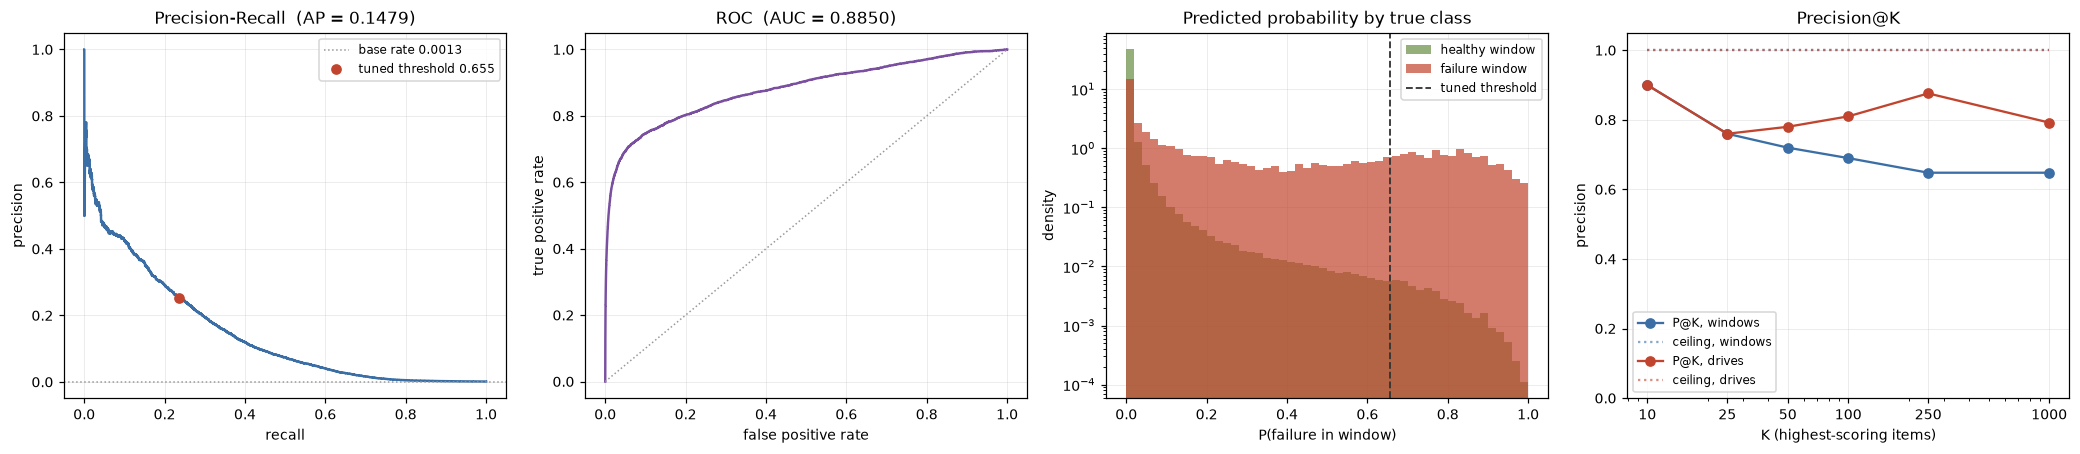

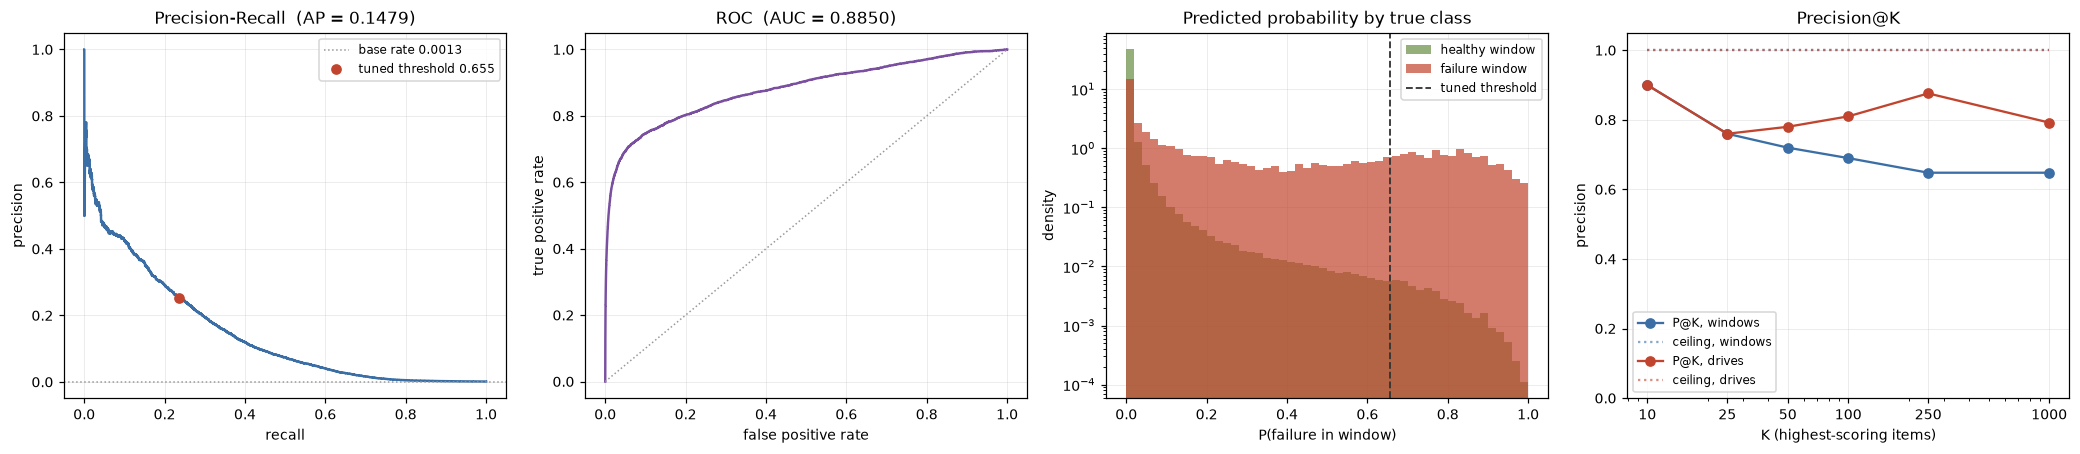

In [16]:
results = ap.evaluate_archive_final(model, loaders, bundle, tcfg, device,
                                    pk_ks=(10, 25, 50, 100, 250, 1000))
results["history"] = history
ap.plot_evaluation(results, ks=(10, 25, 50, 100, 250, 1000),
                   save_path=f"{FIG_DIR}/2022x_step3_evaluation.png")

In [ ]:
# The selected model is the 'baseline' row of the experiment log: tested on the same
# stride-30 windows as every variation in 4b, at the threshold its validation run chose.
# (The stride-1 numbers above stay the headline figures; this row is for comparison.)
# Its weights are checkpointed like every variation's, so it can win the Best Model sheet.
baseline_test = ox.evaluate_on_test(model, test_monitor, run.val_threshold, device)
baseline_cfg = ox.describe_config(tcfg, float(best.train_positive_ratio), model)
baseline_cfg["checkpoint"] = ox.save_checkpoint(
    model, "models/experiments/baseline.pt", tcfg, float(best.train_positive_ratio))
EXP_LOG.add("baseline", baseline_cfg, run.history, run.diagnostics, baseline_test,
            seconds=run.seconds, eval_protocol=ox.eval_protocol(val_monitor, test_monitor))
EXP_LOG.save()

### The test phase, one verdict per window

The threshold is the only quantity carried out of validation, and it was fixed before the
test split was touched. Below, every tiling window of every test drive gets a single
call — **did this drive fail within 30 days of this window ending, yes or no** — scored
against the truth.

This is the tiling window set, so each test drive-day is judged exactly once.

In [18]:
thr = results["best_threshold"]
pred = ap.predict_windows(model, tiles["test"], device, threshold=thr, tag="test")

tp = int(((pred.predicted_fail == 1) & (pred.actual_fail == 1)).sum())
fp = int(((pred.predicted_fail == 1) & (pred.actual_fail == 0)).sum())
fn = int(((pred.predicted_fail == 0) & (pred.actual_fail == 1)).sum())
tn = int(((pred.predicted_fail == 0) & (pred.actual_fail == 0)).sum())

print(f"\nPER-WINDOW VERDICTS -- {len(pred):,} tiling windows over "
      f"{pred.drive_index.nunique():,} test drives, threshold {thr:.4f}\n")
print(f"  predicted FAIL ....... {int(pred.predicted_fail.sum()):,}")
print(f"  actually  FAIL ....... {int(pred.actual_fail.sum()):,}")
print(f"  correct .............. {tp + tn:,} of {len(pred):,} "
      f"({100*(tp+tn)/len(pred):.4f}% accuracy)")
print(f"  TP {tp:,}   FP {fp:,}   FN {fn:,}   TN {tn:,}")
print(f"  precision {tp/max(tp+fp,1):.4f}   recall {tp/max(tp+fn,1):.4f}")
print(f"\n  note: 'accuracy' here is dominated by the {100*(1-pred.actual_fail.mean()):.3f}% "
      f"of windows that are negative -- always saying 'no fail' would score "
      f"{100*(1-pred.actual_fail.mean()):.4f}%.")

    test: 1/755 batches (  0.1%, 0s)


    test: 76/755 batches ( 10.1%, 3s)


    test: 151/755 batches ( 20.0%, 5s)


    test: 226/755 batches ( 29.9%, 7s)


    test: 301/755 batches ( 39.9%, 9s)


    test: 376/755 batches ( 49.8%, 12s)


... (2 outputs left out)

    test: 601/755 batches ( 79.6%, 19s)


    test: 676/755 batches ( 89.5%, 21s)


    test: 751/755 batches ( 99.5%, 23s)



PER-WINDOW VERDICTS -- 3,088,649 tiling windows over 82,609 test drives, threshold 0.6553

  predicted FAIL ....... 5,394
  actually  FAIL ....... 7,424
  correct .............. 3,080,815 of 3,088,649 (99.7464% accuracy)
  TP 2,492   FP 2,902   FN 4,932   TN 3,078,323
  precision 0.4620   recall 0.3357

  note: 'accuracy' here is dominated by the 99.760% of windows that are negative -- always saying 'no fail' would score 99.7596%.


In [19]:
# Every window of a few drives that really failed: the verdict as the run produced it.
failed_drives = (pred[pred.actual_fail == 1].drive_index.drop_duplicates().head(3))
for gidx in failed_drives:
    sub = pred[pred.drive_index == gidx].sort_values("window_start")
    print(f"\ndrive {sub.serial_number.iloc[0]}  --  {len(sub)} windows "
          f"covering {sub.window_start.min():%Y-%m-%d} .. {sub.window_end.max():%Y-%m-%d}")
    show = sub[["window_in_drive", "window_start", "window_end", "risk",
                "predicted_fail", "actual_fail"]].copy()
    show["verdict"] = np.where(show.predicted_fail == 1, "FAIL", "no fail")
    show["truth"] = np.where(show.actual_fail == 1, "FAIL", "no fail")
    print(show.tail(12)[["window_in_drive", "window_start", "window_end",
                         "risk", "verdict", "truth"]].to_string(index=False))


drive 1040A00VF97G  --  36 windows covering 2022-01-01 .. 2024-12-01
 window_in_drive window_start window_end     risk verdict   truth
              24   2023-12-22 2024-01-20 0.003496 no fail no fail
              25   2024-01-21 2024-02-19 0.003274 no fail no fail
              26   2024-02-20 2024-03-20 0.002882 no fail no fail
              27   2024-03-21 2024-04-19 0.003924 no fail no fail
              28   2024-04-20 2024-05-19 0.002353 no fail no fail
              29   2024-05-20 2024-06-18 0.004130 no fail no fail
              30   2024-06-19 2024-07-18 0.003634 no fail no fail
              31   2024-07-19 2024-08-17 0.003869 no fail no fail
              32   2024-08-18 2024-09-16 0.002739 no fail no fail
              33   2024-09-17 2024-10-16 0.002867 no fail no fail
              34   2024-10-17 2024-11-15 0.005040 no fail    FAIL
              35   2024-11-02 2024-12-01 0.003294 no fail    FAIL

drive 1040A0C9F97G  --  8 windows covering 2022-01-01 .. 2022-08-01
 wi

  saved results/figures/2022x_step4_drive_histograms.png


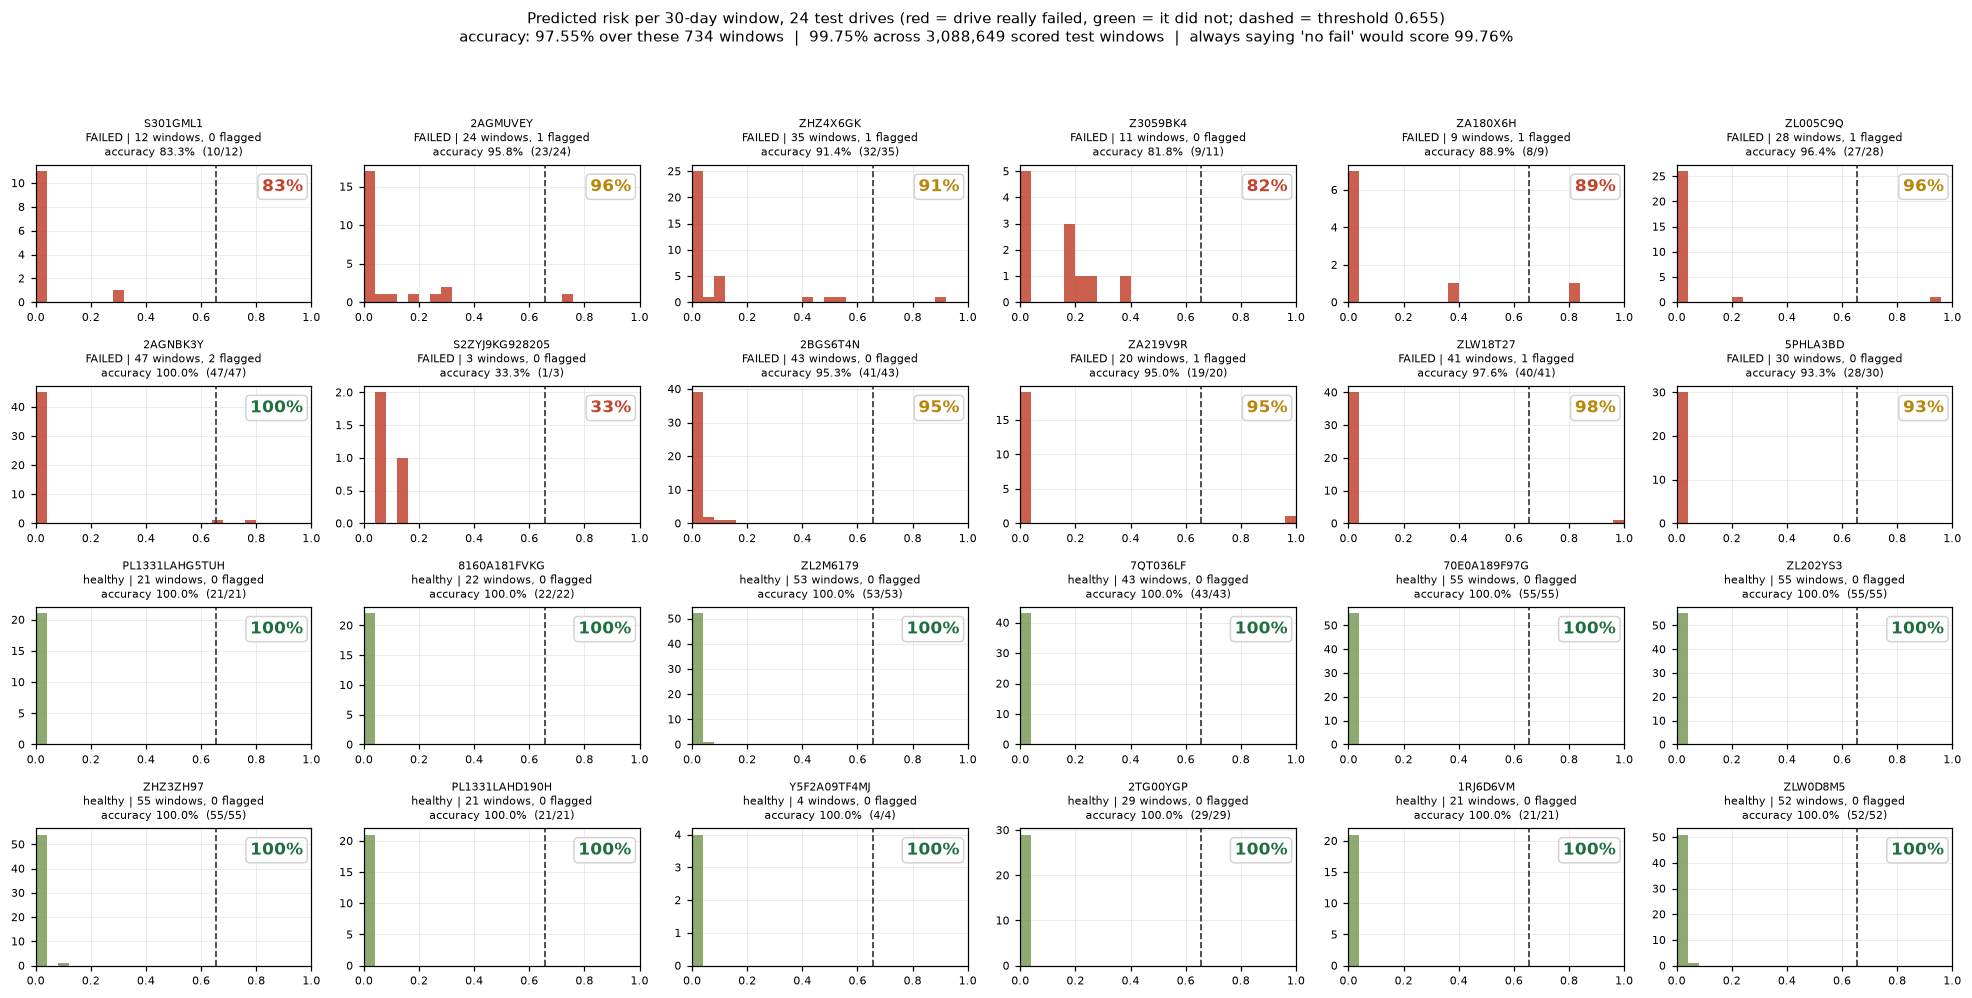


24 drives plotted, one histogram each: the distribution of that drive's 30-day windows over predicted risk.


In [20]:
fig, picks = ap.plot_drive_histograms(
    pred, n_drives=24, threshold=thr, seed=SEED,
    save_path=f"{FIG_DIR}/2022x_step4_drive_histograms.png")
print(f"\n{len(picks)} drives plotted, one histogram each: the distribution of that "
      f"drive's 30-day windows over predicted risk.")

---
## 4b — Automated experiment pipeline: every variation, one winner

One cell runs the whole search with no manual steps. For each variation it

1. builds the network,
2. trains it with **early stopping** on validation PR-AUC (patience 3, `min_delta` 0.001,
   best weights restored) and the **overfitting rule** from §4 watching the train-probe
   vs validation gap every epoch,
3. saves the restored best weights as a checkpoint (`models/experiments/<name>.pt`),
4. scores train, validation and test with those weights: PR-AUC, ROC-AUC, loss,
   balanced accuracy, accuracy, precision, recall, F1,
5. rewrites `results/experiments_results.xlsx`, so an interruption loses at most the run
   in progress.

When every variation is in, the **winner is chosen on validation PR-AUC**, its checkpoint
is reloaded, and it is scored **once on the full stride-1 test set** (~89M windows).
Intermediate epochs are scored at stride 30, the same windows as `cnn_search`, to keep
each run fast.

**Why the winner is chosen on validation, never on test.** With nine-plus candidates,
the one with the highest test score is partly the one that got luckiest on this test
split, so its test number would overstate how it does on new drives. Choosing on
validation leaves the test number an honest estimate.

Variations move **one knob at a time** away from the search winner (`baseline`, trained
above), so each row isolates one change:

| variation | what changes |
|---|---|
| `shallow` / `deeper` | two blocks fewer / one more (doubled dilation) |
| `no_dilation` | same depth, every dilation 1: the receptive field shrinks below the 30-day window (21 days for the 5-block winner) |
| `kernel_5` | kernel 5 instead of 3 |
| `narrow` / `wide` | half / double the hidden width |
| `dropout_0.3`, `weight_decay_1e-4` | stronger regularisation |
| `lr_3e-03`, `lr_3e-04` | learning rate x3 / divided by 3 |

For a full grid instead, swap in `ox.grid_variations({...})` (commented in the cell).

**The workbook:**

| sheet | contents |
|---|---|
| `Best Model` | the winner: configuration, best / stopped / divergence epoch, verdict, every metric on train · validation · test, and the full-test pass |
| `Summary Table` | the leaderboard: one row per variation with hyperparameters, best and stopped epoch, **Overfitting Triggered (Yes/No)**, and each metric for train · val · test side by side. Ranked by validation PR-AUC |
| `Stopping Rules` | the three stopping conditions with their settings, the overfitting limits, and which condition stopped each run (best epoch, stopped epoch, epochs after best) |
| `Epoch History` | every epoch of every run: loss, PR-AUC, ROC-AUC, balanced accuracy, precision, recall, F1, gaps, flags |
| `Configs`, `Diagnostics`, `Test_PrecisionAtK`, `Full Test` | settings incl. checkpoint path, divergence details, Precision@K, the winner's full test |
| `C01_…` | one per variation: its epochs with Excel line charts of train vs validation |

**Cost.** Each variation takes roughly 15–50 minutes, and the full test pass about 30.
The pipeline **resumes**: a variation already in the workbook is skipped. Set
`RUN_SWEEP=0` to skip training and only rebuild the report from the log.

In [ ]:
RUN_SWEEP = os.environ.get("RUN_SWEEP", "1") == "1"
BASE_SHAPE = {"dilations": BEST_DILATIONS, "kernel_size": int(best.kernel_size),
              "hidden_dim": int(best.hidden_dim), "dropout": float(best.dropout),
              "weight_decay": float(best.weight_decay), "lr": float(best.lr)}
VARIATIONS = ox.default_variations(BASE_SHAPE)
# A full grid instead (16 runs here -- grids multiply fast):
# VARIATIONS = ox.grid_variations({"dilations": [(1, 2, 4), (1, 2, 4, 8, 16)],
#                                  "hidden_dim": [64, 128], "dropout": [0.1, 0.3],
#                                  "lr": [3e-4, 1e-3]})
# Any entry is {"name": ..., <TrainConfig field or train_positive_ratio>: value}.
print(pd.DataFrame(VARIATIONS).fillna("").to_string(index=False))

if RUN_SWEEP:
    BEST = ox.run_experiments(
        VARIATIONS, tcfg, bundle, val_monitor, train_probe, test_monitor, device, EXP_LOG,
        test_full_ds=bundle.datasets["test"],          # the winner's full stride-1 test
        select_by="val_pr_auc", rule=RULE,
        es_kwargs={k: v for k, v in ES.items() if k != "patience"},
        train_positive_ratio=float(best.train_positive_ratio), seed=SEED,
        fig_dir=FIG_DIR)

In [ ]:
sweep = EXP_LOG.summary()
sweep = sweep[sweep.model_type == "cnn"]
cols = ["rank_by_val", "variation", "layers", "dilations", "kernel_size", "hidden_dim",
        "dropout", "lr", "parameters", "best_epoch", "stopped_epoch", "divergence_epoch",
        "overfitting_triggered", "train_pr_auc", "val_pr_auc", "test_pr_auc",
        "pr_auc_gap_pct", "test_roc_auc", "test_bal_acc", "test_f1", "test_P@100_drives"]
print("SUMMARY TABLE -- ranked by validation PR-AUC; test is read, never used to choose\n")
print(sweep[[c for c in cols if c in sweep]].to_string(
    index=False, float_format=lambda v: f"{v:.4f}"))

win = EXP_LOG.best_model("val_pr_auc")
full = EXP_LOG.frames["Full Test"]
full = full[full.variation == win.variation] if "variation" in full else full.iloc[0:0]
print(f"\nBEST MODEL: {win.variation}  ({win.layers} blocks, dilations {win.dilations}, "
      f"kernel {win.kernel_size}, width {win.hidden_dim}, dropout {win.dropout}, "
      f"lr {win.lr:g})")
print(f"  best epoch {win.best_epoch}, stopped {win.stopped_epoch}, overfitting "
      f"triggered: {win.overfitting_triggered} -- {win.status}")
print(f"  {'':<18}{'train':>9}{'val':>9}{'test':>9}"
      + (f"{'full test':>11}" if len(full) else ""))
for m, label in ox.ExperimentLog.METRICS:
    line = (f"  {label:<18}{win[f'train_{m}']:>9.4f}{win[f'val_{m}']:>9.4f}"
            f"{win[f'test_{m}']:>9.4f}")
    if len(full):
        line += f"{full.iloc[0][m]:>11.4f}"
    print(line)
print(f"\nfull report: {EXP_LOG.path} (sheet 'Best Model' first)")
ox.plot_variation_gaps(EXP_LOG, RULE, save_path=f"{FIG_DIR}/2022x_step4b_variations.png")

---
## 5 — XGBoost on the same windows, head to head with the CNN

A tree model cannot take a `(30, 46)` tensor, so each **tiling** window is reduced to a
row of summary features — per channel, its last day, its 30-day mean, and its
first-to-last change: 46 channels × 3 = 138 columns. The table is built for all three
splits, from the same drive-grouped split the CNN used, so no drive crosses a boundary.

**How XGBoost is trained.**

* `tree_method="hist"` on the GPU when there is one: the 10.5M-row training table fits in
  a few minutes rather than hours.
* **Early stopping on validation PR-AUC** (`aucpr`), the same criterion the CNN stops on,
  with 100 rounds of patience. A train probe of the same size as validation is scored
  every round too, so XGBoost goes through the same overfitting rule as the CNN, and it
  is logged to the same workbook.
* **No imbalance weighting.** PR-AUC and Precision@K only depend on the ranking, and the
  decision threshold is tuned on validation — so `scale_pos_weight` would add a second
  correction on top of the threshold for no gain.
* **The threshold comes from validation only**, by best F1, then is frozen for test —
  exactly how the CNN's threshold was chosen.

**How the comparison is kept fair.** Both models are scored on the **same 3.1M tiling
test windows** of the same 82k test drives: the CNN's scores are the per-window verdicts
from §4, and the cell asserts that the windows and labels line up row for row. XGBoost
is not scored on the 89M stride-1 windows the CNN was also tested on in §4 — flattening
those would take ~50 GB — so the table below, not the §4 summary, is the like-for-like
read.

In [23]:
t0 = time.time()
Xtr, ytr, feat_cols = ap.window_table_features(
    store, tiles["train"], aggregates=("last", "mean", "delta"))
Xva, yva, _ = ap.window_table_features(
    store, tiles["val"], aggregates=("last", "mean", "delta"))
Xte, yte, _ = ap.window_table_features(
    store, tiles["test"], aggregates=("last", "mean", "delta"))
print(f"\nbuilt in {time.time()-t0:.0f}s   train {Xtr.shape}   val {Xva.shape}   "
      f"test {Xte.shape}")
print(f"{len(feat_cols)} features = {len(store.feature_names)} channels x "
      f"3 aggregates (last, mean, delta)")

    features 500,000/10,519,256 (  4.8%, 363s)


    features 2,500,000/10,519,256 ( 23.8%, 421s)


    features 4,500,000/10,519,256 ( 42.8%, 484s)


    features 6,500,000/10,519,256 ( 61.8%, 523s)


    features 8,500,000/10,519,256 ( 80.8%, 570s)


    features 10,500,000/10,519,256 ( 99.8%, 605s)


... (2 outputs left out)

  feature table 1,860,545 x 138 float32 (1.0 GB), 4,449 positive (0.2391%)


    features 500,000/3,088,649 ( 16.2%, 20s)


    features 2,500,000/3,088,649 ( 80.9%, 36s)


  feature table 3,088,649 x 138 float32 (1.7 GB), 7,424 positive (0.2404%)

built in 691s   train (10519256, 138)   val (1860545, 138)   test (3088649, 138)
138 features = 46 channels x 3 aggregates (last, mean, delta)


In [24]:
# The CNN is finished with the GPU; hand its cached blocks back before XGBoost copies
# the training table over.
torch.cuda.empty_cache()
xgb_device = "cuda" if torch.cuda.is_available() else "cpu"

# A train probe for XGBoost, as for the CNN: training rows the size of the validation
# table, at their natural prevalence (tiling windows are not resampled), scored every
# round. Validation goes LAST in eval_set because early stopping watches the last set,
# and "aucpr" goes last in eval_metric for the same reason.
rng = np.random.default_rng(SEED)
probe_rows = np.sort(rng.choice(len(ytr), size=min(len(ytr), len(yva)), replace=False))
Xtr_probe, ytr_probe = Xtr[probe_rows], ytr[probe_rows]

xgb_clf = xgb.XGBClassifier(
    n_estimators=3000, learning_rate=0.05, max_depth=8, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, max_bin=256,
    tree_method="hist", device=xgb_device,
    objective="binary:logistic", eval_metric=["logloss", "auc", "aucpr"],
    early_stopping_rounds=100, random_state=SEED,
)
t0 = time.time()
xgb_clf.fit(Xtr, ytr, eval_set=[(Xtr_probe, ytr_probe), (Xva, yva)], verbose=100)
# The per-round curves are kept in evals_result(). A list-valued eval_metric must not
# reach set_params(device=...) below: xgboost 3.4 hands it to the booster as one string
# and fails, so it goes back to the single metric early stopping used.
xgb_clf.set_params(eval_metric="aucpr")
print(f"\nbest iteration {xgb_clf.best_iteration} of {xgb_clf.n_estimators} "
      f"(val PR-AUC {xgb_clf.best_score:.4f})  --  {time.time()-t0:.0f}s on {xgb_device}")

[0]	validation_0-logloss:0.01278	validation_0-auc:0.84749	validation_0-aucpr:0.23752	validation_1-logloss:0.01299	validation_1-auc:0.84385	validation_1-aucpr:0.23294


[100]	validation_0-logloss:0.00877	validation_0-auc:0.93013	validation_0-aucpr:0.45186	validation_1-logloss:0.00947	validation_1-auc:0.91736	validation_1-aucpr:0.37452


[200]	validation_0-logloss:0.00834	validation_0-auc:0.93881	validation_0-aucpr:0.49532	validation_1-logloss:0.00935	validation_1-auc:0.91957	validation_1-aucpr:0.38596


[300]	validation_0-logloss:0.00804	validation_0-auc:0.94568	validation_0-aucpr:0.52494	validation_1-logloss:0.00930	validation_1-auc:0.92016	validation_1-aucpr:0.39020


[400]	validation_0-logloss:0.00779	validation_0-auc:0.95087	validation_0-aucpr:0.54837	validation_1-logloss:0.00929	validation_1-auc:0.92031	validation_1-aucpr:0.39178


[500]	validation_0-logloss:0.00754	validation_0-auc:0.95544	validation_0-aucpr:0.57068	validation_1-logloss:0.00928	validation_1-auc:0.92045	validation_1-aucpr:0.39295


[569]	validation_0-logloss:0.00739	validation_0-auc:0.95825	validation_0-aucpr:0.58327	validation_1-logloss:0.00928	validation_1-auc:0.92034	validation_1-aucpr:0.39289



best iteration 469 of 3000 (val PR-AUC 0.3932)  --  44s on cuda


In [25]:
# Predict on the CPU: the tables are NumPy arrays in host memory, and scoring them with a
# GPU booster makes XGBoost warn and fall back to a copy anyway.
xgb_clf.set_params(device="cpu")
p_va = xgb_clf.predict_proba(Xva)[:, 1]
p_te = xgb_clf.predict_proba(Xte)[:, 1]

# Threshold from validation only, then frozen -- the same rule the CNN followed.
thr_xgb, f1_va = ap.sweep_threshold(yva, p_va)
xgb_val = bw.compute_metrics(yva, p_va, thr_xgb)
xgb_half = bw.compute_metrics(yte, p_te, 0.5)
xgb_test = bw.compute_metrics(yte, p_te, thr_xgb)
print(f"threshold tuned on validation: {thr_xgb:.4f}  (val F1 {f1_va:.4f})\n")
for name, m in (("val   @tuned", xgb_val), ("test  @0.50", xgb_half),
                ("test  @tuned", xgb_test)):
    print("  " + bw.format_metrics(name, m))
print()

KS = (10, 25, 50, 100, 250, 1000)
g_te, _ = tiles["test"].locate(np.arange(tiles["test"].n_windows, dtype=np.int64))
xgb_pk_win = bw.print_precision_at_k(
    yte, p_te, "XGBOOST TEST PRECISION@K -- ranking windows", KS)
drive_codes, p_drv_xgb, y_drv = ap.drive_level_scores(p_te, yte, g_te)
xgb_pk_drv = bw.print_precision_at_k(
    y_drv, p_drv_xgb, "XGBOOST TEST PRECISION@K -- ranking DRIVES (each by its worst window)",
    KS)

imp_xgb = pd.DataFrame({"feature": feat_cols, "gain": xgb_clf.feature_importances_})
imp_xgb = imp_xgb.sort_values("gain", ascending=False).head(15).reset_index(drop=True)
imp_xgb.index += 1
print("\nwhat XGBoost relies on most (share of total gain):")
print(imp_xgb.to_string())

threshold tuned on validation: 0.2172  (val F1 0.4408)

  val   @tuned           PR-AUC 0.3932 | ROC-AUC 0.9205 | P 0.4900 | R 0.4005 | F1 0.4408 | thr 0.2172 | TP 1782 FP 1855 FN 2667 TN 1854241
  test  @0.50            PR-AUC 0.3875 | ROC-AUC 0.9186 | P 0.6992 | R 0.2411 | F1 0.3586 | thr 0.5000 | TP 1790 FP 770 FN 5634 TN 3080455
  test  @tuned           PR-AUC 0.3875 | ROC-AUC 0.9186 | P 0.4950 | R 0.3968 | F1 0.4405 | thr 0.2172 | TP 2946 FP 3006 FN 4478 TN 3078219



XGBOOST TEST PRECISION@K -- ranking windows
  3,088,649 items ranked, 7,424 positive (base rate 0.240%)
       K |   hits |  precision |    best |  recall@K |     lift
  -------+--------+------------+---------+-----------+---------
      10 |     10 |     1.0000 |  1.0000 |    0.0013 |   416.0x
      25 |     24 |     0.9600 |  1.0000 |    0.0032 |   399.4x
      50 |     49 |     0.9800 |  1.0000 |    0.0066 |   407.7x
     100 |     98 |     0.9800 |  1.0000 |    0.0132 |   407.7x
     250 |    232 |     0.9280 |  1.0000 |    0.0312 |   386.1x
    1000 |    857 |     0.8570 |  1.0000 |    0.1154 |   356.5x
XGBOOST TEST PRECISION@K -- ranking DRIVES (each by its worst window)
  82,609 items ranked, 3,713 positive (base rate 4.495%)
       K |   hits |  precision |    best |  recall@K |     lift
  -------+--------+------------+---------+-----------+---------
      10 |     10 |     1.0000 |  1.0000 |    0.0027 |    22.2x
      25 |     24 |     0.9600 |  1.0000 |    0.0065 |    21.4x
 

                   feature      gain
1   smart_197_raw_d7__last  0.365464
2     smart_5_raw_d1__last  0.151739
3       smart_5_raw__delta  0.044702
4   smart_197_raw_d7__mean  0.039978
5     smart_5_raw_d7__mean  0.037540
6     smart_4_raw_d1__mean  0.019799
7      smart_197_raw__mean  0.017686
8        smart_5_raw__mean  0.016566
9           observed__mean  0.013565
10   smart_12_raw_d1__mean  0.013233
11    smart_5_raw_d7__last  0.011221
12  smart_198_raw_d7__last  0.010156
13    smart_4_raw_d1__last  0.009836
14    smart_4_raw_d7__last  0.009310
15          observed__last  0.008020


  wrote results/model_experiments.xlsx (10 runs)
XGBOOST OVERFITTING DIAGNOSTICS -- best round 470, early_stopping_rounds (100 without a val PR-AUC gain)
  divergence begins ...... round 471
  gaps at best round ..... PR-AUC +43.4%  ROC-AUC +3.6%  loss +21.7%
  verdict ................ overfit at best epoch


  saved results/figures/2022x_step5_xgboost_divergence.png


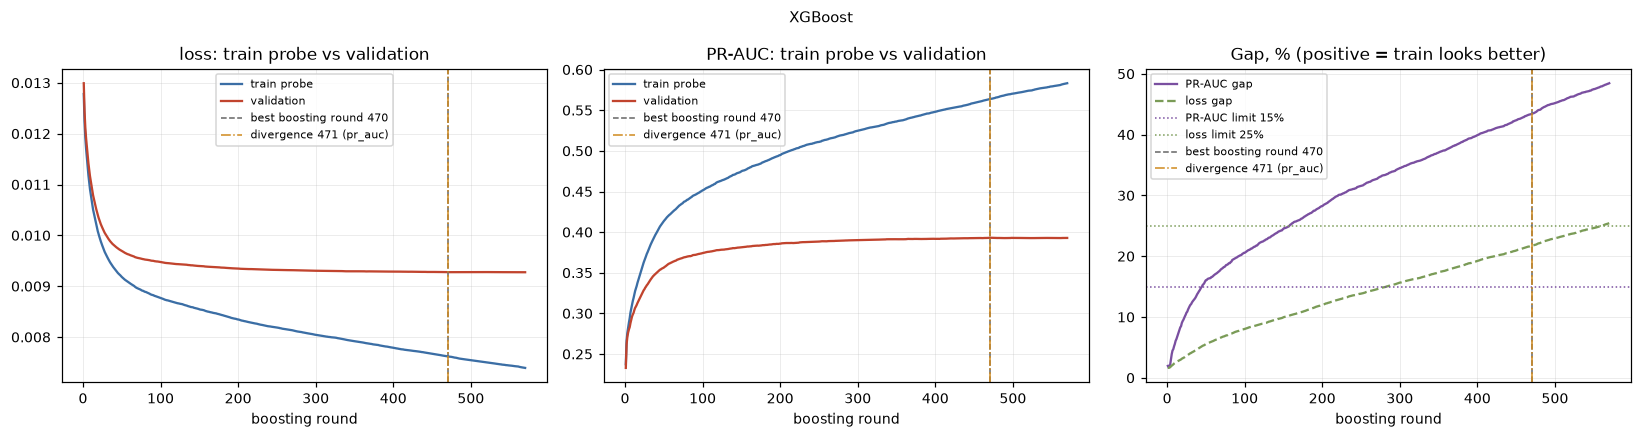

In [26]:
# XGBoost through the same overfitting rule, with a boosting round in place of an epoch.
# A single round moves the curves far less than an epoch does, so a trend has to hold
# for 50 rounds rather than 2 before it counts as divergence.
import dataclasses
XGB_RULE = dataclasses.replace(RULE, min_consecutive=50)
xgb_hist = ox.xgb_history(xgb_clf, XGB_RULE, y_probe=ytr_probe, y_val=yva)
xgb_best_round = int(xgb_clf.best_iteration) + 1
xgb_stop = ("early_stopping_rounds (100 without a val PR-AUC gain)"
            if len(xgb_hist) < xgb_clf.n_estimators else "n_estimators")
xgb_diag = ox.diagnose(xgb_hist, xgb_best_round, XGB_RULE, xgb_stop)
xgb_test_log = ox.evaluate_on_test(None, None, thr_xgb, None, ks=KS,
                                   probs=p_te, targets=yte, codes=g_te)
xgb_conf = {k: v for k, v in xgb_clf.get_params().items()
            if k in ("n_estimators", "learning_rate", "max_depth", "min_child_weight",
                     "subsample", "colsample_bytree", "max_bin")}
xgb_conf.update({"best_iteration": int(xgb_clf.best_iteration),
                 "features": len(feat_cols)})
EXP_LOG.add("xgboost", xgb_conf, xgb_hist, xgb_diag, xgb_test_log, model_type="xgboost",
            eval_protocol="train/val tiling, test tiling")
EXP_LOG.save()

print(f"XGBOOST OVERFITTING DIAGNOSTICS -- best round {xgb_best_round}, "
      f"{xgb_diag['stop_reason']}")
print(f"  divergence begins ...... round {xgb_diag['divergence_epoch'] or 'not observed'}")
print(f"  gaps at best round ..... PR-AUC {xgb_diag['pr_auc_gap_pct_at_best']:+.1f}%  "
      f"ROC-AUC {xgb_diag['roc_auc_gap_pct_at_best']:+.1f}%  "
      f"loss {xgb_diag['loss_gap_pct_at_best']:+.1f}%")
print(f"  verdict ................ {xgb_diag['status']}")
ox.plot_divergence(xgb_hist, xgb_diag, XGB_RULE, title="XGBoost", xlabel="boosting round",
                   save_path=f"{FIG_DIR}/2022x_step5_xgboost_divergence.png")
del Xtr_probe, ytr_probe

In [27]:
# `pred` holds the CNN's score for exactly these tiling windows (§4). Same windows, same
# order, same labels -- asserted, not assumed.
assert len(pred) == len(yte)
assert np.array_equal(pred.drive_index.to_numpy(), g_te)
assert np.array_equal(pred.actual_fail.to_numpy(), yte.astype(int))
p_cnn = pred.risk.to_numpy()

cnn_test = bw.compute_metrics(yte, p_cnn, thr)
_, p_drv_cnn, _ = ap.drive_level_scores(p_cnn, yte, g_te)
cnn_pk_win = bw.precision_at_k_table(yte, p_cnn, KS)
cnn_pk_drv = bw.precision_at_k_table(y_drv, p_drv_cnn, KS)

comparison = pd.DataFrame([
    {"model": name, "PR-AUC": m["pr_auc"], "ROC-AUC": m["roc_auc"],
     "threshold": m["threshold"], "precision": m["precision"], "recall": m["recall"],
     "F1": m["f1"], "TP": m["tp"], "FP": m["fp"], "FN": m["fn"]}
    for name, m in (("CNN", cnn_test), ("XGBoost", xgb_test))
]).set_index("model")

print(f"CNN vs XGBOOST -- the same {len(yte):,} tiling test windows over "
      f"{len(y_drv):,} test drives")
print(f"(base rate {100*yte.mean():.3f}% of windows; each model at its own "
      f"validation-tuned threshold)\n")
print(comparison.to_string(float_format=lambda v: f"{v:.4f}"))

pk_compare = pd.DataFrame({
    "K": list(KS),
    "CNN drive hits": cnn_pk_drv.hits.to_numpy(),
    "XGBoost drive hits": xgb_pk_drv.hits.to_numpy(),
    "CNN drive precision": cnn_pk_drv.precision.to_numpy(),
    "XGBoost drive precision": xgb_pk_drv.precision.to_numpy(),
    "CNN window precision": cnn_pk_win.precision.to_numpy(),
    "XGBoost window precision": xgb_pk_win.precision.to_numpy(),
})
print(f"\nPrecision@K -- of the K drives (or windows) each model flags first, "
      f"how many really failed:\n")
print(pk_compare.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

CNN vs XGBOOST -- the same 3,088,649 tiling test windows over 82,609 test drives
(base rate 0.240% of windows; each model at its own validation-tuned threshold)

         PR-AUC  ROC-AUC  threshold  precision  recall     F1    TP    FP    FN
model                                                                          
CNN      0.3250   0.9050     0.6553     0.4620  0.3357 0.3888  2492  2902  4932
XGBoost  0.3875   0.9186     0.2172     0.4950  0.3968 0.4405  2946  3006  4478

Precision@K -- of the K drives (or windows) each model flags first, how many really failed:

   K  CNN drive hits  XGBoost drive hits  CNN drive precision  XGBoost drive precision  CNN window precision  XGBoost window precision
  10               8                  10               0.8000                   1.0000                0.8000                    1.0000
  25              22                  24               0.8800                   0.9600                0.8400                    0.9600
  50              4

In [ ]:
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
for name, p, col in (("CNN", p_cnn, "#3b6ea5"), ("XGBoost", p_te, "#c1442e")):
    prec, rec, _ = precision_recall_curve(yte, p)
    ax.plot(rec, prec, color=col, lw=1.2,
            label=f"{name}  (PR-AUC {comparison.loc[name, 'PR-AUC']:.4f})")
ax.axhline(yte.mean(), color="0.5", ls="--", lw=0.8,
           label=f"random ({100*yte.mean():.2f}%)")
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("Precision-recall, test tiling windows")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(KS, pk_compare["CNN drive precision"], "o-", color="#3b6ea5", label="CNN")
ax.plot(KS, pk_compare["XGBoost drive precision"], "o-", color="#c1442e",
        label="XGBoost")
ax.set_xscale("log"); ax.set_xticks(KS); ax.set_xticklabels([str(k) for k in KS])
ax.set_ylim(0, 1.02)
ax.set_xlabel("K drives flagged"); ax.set_ylabel("precision@K")
ax.set_title("Drives: of the top K flagged, the share that failed")
ax.legend(fontsize=8)
for a in axes:
    a.grid(alpha=0.25, linewidth=0.6); a.set_axisbelow(True)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/2022x_step5_cnn_vs_xgboost.png", dpi=130, bbox_inches="tight")
print(f"  saved {FIG_DIR}/2022x_step5_cnn_vs_xgboost.png")
plt.show()

del Xva; gc.collect()     # p_va stays: the comparison workbook at the end needs it

---
## 5b — A transformer on the same windows

XGBoost beat the CNN above, and its gain ranking says why: the top features are each
channel's **last day** and its **first-to-last change** (`smart_197_raw_d7__last`,
`smart_5_raw_d1__last`, `smart_5_raw__delta`). The CNN can compute these, but it has to
learn them through five convolution blocks and a mean/max/last pool. The transformer here
is built to start from them and keep what convolution does well:

```
[CLS]  [LAST]  [MEAN]  [DELTA]  day 1  day 2  ...  day 30      <- 34 tokens, d = 128
  |       \______|______/          \_______________/
  |       the window summary         one token per day
  |       XGBoost reads              (46 channels -> 128)
  +--- 3 pre-norm encoder layers, 4 heads, attention over all 34 tokens ---+
                       head reads [CLS] + the last day  ->  1 logit
```

* **Day tokens + learned positions** — attention sees every day from the first layer, so
  the receptive field is the whole window without stacking dilations.
* **Summary tokens** — the last day, the 30-day mean and the change, each through its own
  projection: exactly XGBoost's 3 × 46 view, as tokens the days can attend to and that can
  attend back to the days. The model starts where XGBoost is and uses attention for what a
  summary loses (*when* in the window a counter jumped, whether it is still climbing).
* **[CLS] + last-day readout** — the pooled view plus the most recent state, the one an
  operator acts on.

**Same protocol as the CNN, so only the network differs.** The variations go through
`ox.run_experiments` with the CNN's training stream (4 random windows per drive, 25%
forced positives), the same stride-30 validation monitor and train probe, early stopping on
validation PR-AUC with patience 3, the overfitting rule from §4 and seed 42. They are
logged to the same `results/experiments_results.xlsx` as `model_type = transformer`.

| variation | what changes |
|---|---|
| `tf_summary` | the model above: 3 layers, width 128, dropout 0.1, lr 1e-3 |
| `tf_plain` | **control**: day tokens only, no summary tokens, no [CLS] (mean + last pool) |
| `tf_summary_6layers` | twice the depth |
| `tf_summary_width64` | half the width |
| `tf_summary_lr3e-04` | learning rate ÷ 3 |

The gap between `tf_plain` and `tf_summary` is what the summary tokens add; the gap between
`tf_plain` and the CNN is what attention alone adds. As for the CNN, the winner is chosen
on **validation** PR-AUC and only then read on test.

The runs resume: a variation already in the workbook is skipped. Set `RUN_TRANSFORMER=0` to
skip training and only report from the log. `scripts/run_transformer_comparison.py` runs
this section and the comparison workbook as a plain script.

In [ ]:
import dataclasses
import model_comparison as mc

RUN_TRANSFORMER = os.environ.get("RUN_TRANSFORMER", "1") == "1"
# Everything but the network is inherited from the CNN's TrainConfig.
TF_BASE = dataclasses.replace(tcfg, **mc.TRANSFORMER_BASE)
TF_VARIATIONS = mc.transformer_variations()
print(pd.DataFrame(TF_VARIATIONS).fillna("").to_string(index=False))
with torch.no_grad():
    _tf = bw.build_model(bundle.num_features, cfg.window_days, TF_BASE).to(device)
    print(f"\ntf_summary: input (2, {cfg.window_days}, {bundle.num_features}) -> "
          f"{tuple(_tf(torch.zeros(2, cfg.window_days, bundle.num_features, device=device)).shape)}"
          f", {bw.count_parameters(_tf):,} parameters (the CNN has {bw.count_parameters(model):,})")
    del _tf

if RUN_TRANSFORMER:
    TF_BEST = ox.run_experiments(
        TF_VARIATIONS, TF_BASE, bundle, val_monitor, train_probe, test_monitor, device,
        EXP_LOG, select_by="val_pr_auc", rule=RULE,
        es_kwargs={k: v for k, v in ES.items() if k != "patience"},
        train_positive_ratio=float(best.train_positive_ratio), seed=SEED,
        fig_dir=FIG_DIR, model_type="transformer")

In [ ]:
# CNN and transformer runs on the stride-30 windows every one of them was selected on.
board = EXP_LOG.summary()
board = board[board.model_type.isin(["cnn", "transformer"])]
board = board[board.eval_protocol == board.eval_protocol.mode().iloc[0]]
board = board.sort_values("val_pr_auc", ascending=False)
cols = ["variation", "model_type", "layers", "hidden_dim", "parameters", "best_epoch",
        "stopped_epoch", "overfitting_triggered", "train_pr_auc", "val_pr_auc",
        "test_pr_auc", "pr_auc_gap_pct", "test_roc_auc", "test_f1", "test_P@100_drives"]
print("CNN + TRANSFORMER RUNS -- stride-30 windows, ranked by validation PR-AUC\n")
print(board[cols].to_string(index=False, float_format=lambda v: f"{v:.4f}"))

tf_win = EXP_LOG.best_model("val_pr_auc", model_type="transformer")
cnn_win = EXP_LOG.best_model("val_pr_auc", model_type="cnn")
print(f"\nbest transformer: {tf_win.variation}  val PR-AUC {tf_win.val_pr_auc:.4f}  "
      f"test PR-AUC {tf_win.test_pr_auc:.4f}")
print(f"best CNN:         {cnn_win.variation}  val PR-AUC {cnn_win.val_pr_auc:.4f}  "
      f"test PR-AUC {cnn_win.test_pr_auc:.4f}")
print(f"  -> transformer {100 * (tf_win.val_pr_auc / cnn_win.val_pr_auc - 1):+.1f}% on "
      f"validation, {100 * (tf_win.test_pr_auc / cnn_win.test_pr_auc - 1):+.1f}% on test")
ox.plot_variation_gaps(EXP_LOG, RULE, model_type="transformer",
                       save_path=f"{FIG_DIR}/2022x_step5b_transformer_variations.png")

In [ ]:
# The transformer winner on the same tiling windows as the CNN and XGBoost in §5. Its
# threshold is the best-F1 cut on the tiling validation windows -- XGBoost's rule.
tf_model, tf_cfg = ox.load_checkpoint(EXP_LOG.config_of(tf_win.variation)["checkpoint"],
                                      bundle.num_features, cfg.window_days, device)
p_tf_va = mc.predict_probs(tf_model, tiles["val"], device)
p_tf = mc.predict_probs(tf_model, tiles["test"], device)
thr_tf, _ = ap.sweep_threshold(tiles["val"].labels, p_tf_va)
tf_test = bw.compute_metrics(yte, p_tf, thr_tf)
_, p_drv_tf, _ = ap.drive_level_scores(p_tf, yte, g_te)
tf_pk_win = bw.precision_at_k_table(yte, p_tf, KS)
tf_pk_drv = bw.precision_at_k_table(y_drv, p_drv_tf, KS)
TF_NAME = f"Transformer ({tf_win.variation})"

comparison = pd.concat([comparison, pd.DataFrame([{
    "model": TF_NAME, "PR-AUC": tf_test["pr_auc"], "ROC-AUC": tf_test["roc_auc"],
    "threshold": tf_test["threshold"], "precision": tf_test["precision"],
    "recall": tf_test["recall"], "F1": tf_test["f1"], "TP": tf_test["tp"],
    "FP": tf_test["fp"], "FN": tf_test["fn"]}]).set_index("model")])
pk_compare["Transformer drive hits"] = tf_pk_drv.hits.to_numpy()
pk_compare["Transformer drive precision"] = tf_pk_drv.precision.to_numpy()
pk_compare["Transformer window precision"] = tf_pk_win.precision.to_numpy()

print(f"CNN vs XGBOOST vs TRANSFORMER -- the same {len(yte):,} tiling test windows\n")
print(comparison.to_string(float_format=lambda v: f"{v:.4f}"))
print("\ndrive precision @K:")
print(pk_compare[["K", "CNN drive precision", "XGBoost drive precision",
                  "Transformer drive precision"]].to_string(
    index=False, float_format=lambda v: f"{v:.4f}"))
gain = 100 * (tf_test["pr_auc"] / cnn_test["pr_auc"] - 1)
print(f"\ntransformer vs CNN: PR-AUC {tf_test['pr_auc']:.4f} vs {cnn_test['pr_auc']:.4f} "
      f"({gain:+.1f}%), drive P@100 {tf_pk_drv.set_index('k').loc[100, 'precision']:.2f} "
      f"vs {cnn_pk_drv.set_index('k').loc[100, 'precision']:.2f}")

from sklearn.metrics import precision_recall_curve
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
models3 = (("CNN", p_cnn, "#3b6ea5", "CNN"), ("XGBoost", p_te, "#c1442e", "XGBoost"),
           (TF_NAME, p_tf, "#2e8b57", "Transformer"))
for name, p, col, _ in models3:
    prec, rec, _ = precision_recall_curve(yte, p)
    axes[0].plot(rec, prec, color=col, lw=1.2,
                 label=f"{name}  (PR-AUC {comparison.loc[name, 'PR-AUC']:.4f})")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision")
axes[0].set_title("Precision-recall, test tiling windows"); axes[0].legend(fontsize=8)
for name, _, col, short in models3:
    axes[1].plot(KS, pk_compare[f"{short} drive precision"], "o-", color=col, label=name)
axes[1].set_xscale("log"); axes[1].set_xticks(KS)
axes[1].set_xticklabels([str(k) for k in KS]); axes[1].set_ylim(0, 1.02)
axes[1].set_xlabel("K drives flagged"); axes[1].set_ylabel("precision@K")
axes[1].set_title("Drives: of the top K flagged, the share that failed")
axes[1].legend(fontsize=8)
for a in axes:
    a.grid(alpha=0.25, linewidth=0.6); a.set_axisbelow(True)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/2022x_step5b_cnn_xgb_transformer.png", dpi=130, bbox_inches="tight")
plt.show()
del tf_model; torch.cuda.empty_cache()

---
## 6 — A single decision tree, capped at depth 8

Fitted on the same flattened **tiling** table as XGBoost, so the tree sees every
training drive-day exactly once. A scikit-learn tree is fitted on one CPU core, which is
why this section runs last.

The tree is grown in depth steps **2, 4, 6, 8 and stops at 8**. An earlier run let it grow
without a limit: it reached depth 123 and 28,881 leaves, scored 0.99999 on its training
set, and fell to balanced accuracy 0.63 and PR-AUC 0.06 on test — a memorised training
set, not a model — at an hour of fitting. Depth 8 already shows the whole story (the
train-vs-test gap opening as depth grows) at a fraction of the cost, and depth 8 is also
the depth of every tree inside XGBoost, so the two are directly comparable: one tree
against an ensemble of a few hundred of the same size.

**Accuracy is the wrong lens at this base rate.** Predicting "never fails" scores about
99.8%. Balanced accuracy — the mean of per-class recall — is reported alongside, and it
is the column that moves.

In [ ]:
TREE_DEPTH = 8
tree, ladder = ap.grow_tree_to_full_accuracy(
    Xtr, ytr, Xte, yte, depths=[2, 4, 6, TREE_DEPTH], unbounded=False, seed=SEED)
print()
print(ladder.to_string(index=False))

In [ ]:
final = ladder.iloc[-1]
print(f"FINAL TREE -- max_depth {TREE_DEPTH} (actual {final.actual_depth}), "
      f"{final.leaves:,} leaves, min_samples_leaf=1")
print(f"  training accuracy .... {final.train_accuracy:.8f}")
print(f"  test accuracy ........ {final.test_accuracy:.8f}")
print(f"  training balanced .... {final.train_balanced_acc:.4f}")
print(f"  test balanced ........ {final.test_balanced_acc:.4f}")
print(f"\n  both ACCURACY columns sit at the 'never fails' baseline "
      f"({100 * (1 - ytr.mean()):.3f}%) -- they say nothing here;")
print(f"  the BALANCED columns ({final.train_balanced_acc:.3f} train vs "
      f"{final.test_balanced_acc:.3f} test) are the read, and the gap between")
print(f"  them is how much of the depth-{TREE_DEPTH} tree is fitted to training drives "
      f"rather than to failure.\n")

imp = pd.DataFrame({"feature": feat_cols, "importance": tree.feature_importances_})
imp = imp[imp.importance > 0].sort_values("importance", ascending=False).head(15)
imp.index = range(1, len(imp) + 1)
print("what the tree splits on most:")
print(imp.to_string())

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
x = np.arange(len(ladder))
ax.plot(x, ladder.train_accuracy, "o-", color="#3b6ea5", label="train accuracy")
ax.plot(x, ladder.test_accuracy, "o-", color="#c1442e", label="test accuracy")
ax.set_xticks(x); ax.set_xticklabels(ladder.max_depth.astype(str))
ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy")
ax.set_title("Accuracy is the wrong lens here\n(both columns pinned near 1.0 by the base rate)")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(x, ladder.train_balanced_acc, "o-", color="#3b6ea5", label="train balanced acc")
ax.plot(x, ladder.test_balanced_acc, "o-", color="#c1442e", label="test balanced acc")
ax.set_xticks(x); ax.set_xticklabels(ladder.max_depth.astype(str))
ax.set_xlabel("max_depth"); ax.set_ylabel("balanced accuracy")
ax.set_title("Balanced accuracy: the gap that opens is the overfitting")
ax.legend(fontsize=8)
for a in axes:
    a.grid(alpha=0.25, linewidth=0.6); a.set_axisbelow(True)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/2022x_step6_tree_depth.png", dpi=130, bbox_inches="tight")
print(f"  saved {FIG_DIR}/2022x_step6_tree_depth.png")
plt.show()

In [ ]:
os.makedirs("models", exist_ok=True); os.makedirs("results", exist_ok=True)
ap.save_artifacts(model, bundle, tcfg, results, prefix="models/backblaze_2022x_w30")
xgb_clf.save_model("models/backblaze_2022x_w30_xgb.json")
with open("models/backblaze_2022x_w30_xgb_config.json", "w", encoding="utf-8") as fh:
    json.dump({"feature_columns": feat_cols, "aggregates": ["last", "mean", "delta"],
               "window_days": cfg.window_days, "horizon_days": cfg.horizon_days,
               "threshold": thr_xgb, "best_iteration": int(xgb_clf.best_iteration),
               "params": {k: v for k, v in xgb_clf.get_params().items()
                          if isinstance(v, (int, float, str, bool)) or v is None}},
              fh, indent=2)
print("Saved models/backblaze_2022x_w30_xgb.json and its config")

comparison.to_csv("results/w2022x_cnn_vs_xgboost.csv")
pk_compare.to_csv("results/w2022x_cnn_vs_xgboost_precision_at_k.csv", index=False)
imp_xgb.to_csv("results/w2022x_xgboost_importance.csv")

pd.DataFrame(history).to_csv("results/w2022x_training_history.csv", index=False)
coverage.to_csv("results/w2022x_window_coverage.csv")
cov.to_csv("results/w2022x_per_drive_windows.csv", index=False)
ladder.to_csv("results/w2022x_tree_depth_ladder.csv", index=False)
results["top_drives"].to_csv("results/w2022x_top_drives.csv", index=False)
checks["channel_scores"].to_csv("results/w2022x_channel_label_auc.csv", index=False)
pred.head(2_000_000).to_csv("results/w2022x_window_verdicts.csv", index=False)
pd.concat([results["precision_at_k_windows"].assign(ranked="windows"),
           results["precision_at_k_drives"].assign(ranked="drives")],
          ignore_index=True).to_csv("results/w2022x_precision_at_k.csv", index=False)

with open("results/w2022x_summary.json", "w", encoding="utf-8") as fh:
    json.dump({
        "since_year": SINCE_YEAR,
        "shards": [os.path.basename(p)[:-8] for p in shards],
        "features": list(features),
        "blocklist": report.blocklist,
        "n_drives": int(store.n_drives),
        "n_drive_days": int(store.n_rows),
        "tiling_windows_total": int(total_tiles),
        "tiling_batches_total": int(total_batches),
        "leakage_checks_passed": bool(checks["x_independent_of_label"]),
        "max_channel_auc_vs_label": float(checks["max_channel_auc"]),
        "best_threshold": results["best_threshold"],
        "test_at_tuned": results["test_at_tuned"],
        "xgboost": {"best_iteration": int(xgb_clf.best_iteration),
                    "threshold": thr_xgb,
                    "val_at_tuned": xgb_val,
                    "test_at_tuned": xgb_test,
                    "test_at_half": xgb_half},
        "cnn_on_tiling_test": cnn_test,
        "transformer": {"variation": tf_win.variation, "threshold": thr_tf,
                        "checkpoint": EXP_LOG.config_of(tf_win.variation)["checkpoint"],
                        "test_at_tuned": tf_test},
        "tree_final": {k: (float(v) if isinstance(v, (int, float, np.floating)) else str(v))
                       for k, v in ladder.iloc[-1].to_dict().items()},
    }, fh, indent=2)
print("wrote results/w2022x_*.csv and results/w2022x_summary.json")
EXP_LOG.save()          # results/experiments_results.xlsx: CNN variations, transformers, XGBoost

---
## Summary — CNN vs XGBoost vs transformer vs decision tree

All four models on the **same 3.1M tiling test windows** of the same 82k test drives.
The CNN, XGBoost and the transformer use the threshold each tuned on validation; the tree
never saw validation, so it is cut at 0.5.

The winner is named on two criteria, in order of importance:

1. **drive precision @100** — of the 100 drives a model flags first, the share that
   really failed. This is the decision an operator makes.
2. **PR-AUC** — the quality of the whole ranking.

When the top two sit within 5% of each other on a criterion, it is reported as a tie
rather than a win.

In [ ]:
p_tree = tree.predict_proba(Xte)[:, 1]
tree_test = bw.compute_metrics(yte, p_tree, 0.5)
_, p_drv_tree, _ = ap.drive_level_scores(p_tree, yte, g_te)
tree_pk_drv = bw.precision_at_k_table(y_drv, p_drv_tree, KS)

entries = [
    ("CNN", cnn_test, cnn_pk_drv),
    ("XGBoost", xgb_test, xgb_pk_drv),
    (TF_NAME, tf_test, tf_pk_drv),
    (f"Decision tree (depth {int(final.actual_depth)})", tree_test, tree_pk_drv),
]
rows = []
for name, m, pk in entries:
    pk = pk.set_index("k")
    rows.append({
        "model": name,
        "drive precision @100": pk.loc[100, "precision"],
        "drives hit @100": int(pk.loc[100, "hits"]),
        "drives hit @1000": int(pk.loc[1000, "hits"]),
        "PR-AUC": m["pr_auc"],
        "ROC-AUC": m["roc_auc"],
        "precision": m["precision"],
        "recall": m["recall"],
        "F1": m["f1"],
        "threshold": m["threshold"],
    })
summary = pd.DataFrame(rows).set_index("model")


def verdict(col):
    ranked = summary[col].sort_values(ascending=False)
    (first, a), (second, b) = list(ranked.items())[:2]
    if a <= 0 or (a - b) / a < 0.05:
        return f"{first} and {second} are tied ({a:.4f} vs {b:.4f})"
    return f"{first} ({a:.4f}, next best {second} at {b:.4f})"


rule = "=" * 88
print(rule)
print(f"SUMMARY -- {len(yte):,} test windows over {len(y_drv):,} test drives "
      f"({int(y_drv.sum()):,} failed; window base rate {100*yte.mean():.3f}%)")
print(rule)
print(summary.to_string(float_format=lambda v: f"{v:.4f}"))
print()
print(f"  best at flagging drives (precision @100) ... {verdict('drive precision @100')}")
print(f"  best ranking overall (PR-AUC) ............. {verdict('PR-AUC')}")
print()
print(f"  for reference, not comparable to the table: the CNN on every stride-1 test "
      f"window (§4) scored")
print(f"  PR-AUC {results['test_at_tuned']['pr_auc']:.4f} over "
      f"{results['n_test_windows']:,} overlapping windows.")

summary.to_csv("results/w2022x_model_summary.csv")
print("\nwrote results/w2022x_model_summary.csv")

### The comparison workbook: every CNN variation, every transformer, XGBoost

The table above holds one model per family. `results/model_comparison.xlsx` holds them
**all** — each of the CNN variations from §4b, each transformer from §5b, XGBoost and the
tree — scored on these same tiling test windows, each with its threshold tuned on the
tiling validation windows. A family's winner is its run with the best **validation**
PR-AUC.

| sheet | contents |
|---|---|
| `Overview` | the verdict, each family's winner, how the comparison is kept fair |
| `Head_to_Head` | every model ranked by drive precision @100 then PR-AUC, best per column in green, bar charts |
| `Family_Winners` | one model per family, chosen on validation, with charts |
| `PrecisionAtK` | drive and window Precision@K for every model, with line charts |
| `Stride30_Leaderboard` | every CNN and transformer run on the windows it was selected on |
| `Training`, `Epoch_History` | how each run trained, and validation PR-AUC per epoch |

Scoring a network on the 4.9M tiling validation + test windows takes about a minute, so
this cell takes roughly a quarter of an hour.

In [ ]:
rows = []
for _, cr in EXP_LOG.frames["Configs"].iterrows():
    ck = cr.get("checkpoint")
    if cr["model_type"] not in ("cnn", "transformer") or not isinstance(ck, str) \
            or not os.path.exists(ck):
        continue
    net, ncfg = ox.load_checkpoint(ck, bundle.num_features, cfg.window_days, device)
    note = f"{ncfg.arch}, {bw.count_parameters(net):,} parameters"
    if cr["variation"] == "baseline":
        note += "; the CNN selected in §4 (the search winner)"
    rows.append(mc.score_network(net, cr["variation"], cr["model_type"], tiles, device,
                                 note=note))
    del net; torch.cuda.empty_cache()
rows.append(mc.score_probs("XGBoost", "xgboost", p_va, yva, p_te, yte, g_te,
                           note=f"{xgb_clf.best_iteration + 1} rounds, max_depth 8"))
rows.append(mc.score_probs(f"Decision tree (depth {TREE_DEPTH})", "tree", None, None,
                           p_tree, yte, g_te, threshold=0.5,
                           note="one tree, cut at 0.5 (never saw validation)"))

all_models, all_pk = mc.comparison_table(rows)
all_models.to_csv("results/w2022x_tiling_comparison.csv", index=False)
all_pk.to_csv("results/w2022x_tiling_precision_at_k.csv", index=False)
print(all_models[["rank", "model", "family", "family_winner", "drive_P@100",
                  "drive_P@1000", "test_pr_auc", "test_roc_auc", "val_pr_auc", "f1"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
mc.write_comparison_workbook(all_models, all_pk, "results/model_comparison.xlsx",
                             exp_log_path=EXP_LOG.path)

---
## What these numbers do and do not say

**The label never reached the model.** §2 is an executed experiment, not a promise: the
labels were replaced with noise and the window tensors came back bit-identical. Together
with the audit's blocklist, that is the strongest statement available short of a proof —
the model's ranking comes from SMART telemetry and nothing else.

**The ranking transfers; the base rate is already real.** This is the fleet at its own
prevalence, not a matched cohort, so the precision figures need no discounting before
they are read. Read the **lift** column in Precision@K rather than raw precision, and
prefer the drive-level table — an operator pulls *K disks*, not K windows.

**Tiling and stride-1 answer different questions.** The tiling set judges every
drive-day exactly once, which is what makes the per-window verdict table and the model
comparison honest. The stride-1 set scores every window that exists, which is the right basis for a
ranking metric. Neither is a sample of the other.

**CNN vs XGBoost is a comparison of inputs as much as of models.** The CNN reads all
30 days of every channel in order; XGBoost reads three numbers per channel. If XGBoost
matches the CNN, most of the signal is in the level and trend of a few SMART counters
and the day-by-day shape adds little. If the CNN wins, the order of events inside the
window carries information the summaries throw away. Read the drive-level Precision@K
rows first — that is the decision an operator makes — and PR-AUC second.

**The transformer is the CNN's protocol with a different network.** Same training
stream, same monitors, same stopping rules, same seed — so its gap to the CNN is the
architecture, and its gap to `tf_plain` is the summary tokens. Its gap to XGBoost is
partly the training data too: XGBoost fits every one of the 10.5M tiling training windows,
the networks see 1.1M resampled windows per epoch.

**One tree is not enough, and accuracy cannot tell you so.** At a 0.2% base rate the
depth-8 tree's accuracy is near-perfect on train and test alike while its ranking is far
behind the ensembles — which is exactly why every other number in this notebook is PR-AUC,
Precision@K or balanced accuracy rather than accuracy.

**2022 onward is not the whole archive.** Drive models, capacities and the SMART
attributes actually populated all shift over time; a model fitted on the last few years
is answering a narrower and more current question than one fitted on all thirteen.